# T12 · 연간 Expanding SVR–GARCH–CUSUM (ETF 20종) — canonical 재현 노트북

> **지위**: T12 v2 (`T12v2-lock-1`, `PROTOCOL_LOCK.md`) 의 **처음부터 끝까지 재실행** 노트북이다. 새 분석을 하지 않는다.
> 기존 코드(`src/r2h/annual_expanding`, `scripts/t12_figures.py`, `scripts/t12_semantic_fingerprint.py`)를 import 해서 부르며,
> 어떤 계산도 노트북 안에서 다시 구현하지 않는다.

**무엇을 하는가**

1. 환경·경로·데이터 해시를 확인한다 (숨은 상태 없이, 네트워크 없이).
2. 20 ETF × 검정연도 2020–2026 의 연간 expanding fold 를 **순차(workers=1)로 전부 다시 계산**한다 (약 10–11 분).
3. 새 결과표의 **Semantic Result Fingerprint** 가 기준 run `seq_golden` 과 같은지 assert 한다.
4. 결과표·그림·요약을 다시 만들고, 무엇을 말할 수 있고 무엇을 말할 수 없는지 적는다.

**안 하는 것**

- 임계값·학습기간·검정·플래그 규칙을 바꾸지 않는다 (결과를 본 뒤 바꾸면 `Sensitivity` 로 분리해야 한다 — 이 노트북엔 없다).
- 실제 데이터의 경보를 정탐/오탐(TP/FP)으로 부르지 않는다. 실제 데이터 경보는 **alarm_frequency** 다.
- 인과("RV 가 기각을 일으켰다")·예측·조기경보 주장을 하지 않는다. 2026 은 블라인드 검증이 아니다.
- T11(70:30) 과의 **성능 비교를 하지 않는다** (조건이 다르다 — 9절).
- 원논문(Lee·Kim·Lee 2020) 수치 재현을 주장하지 않는다 (T09 `METHOD_FIDELITY_UNRESOLVED`).

**실행 명령** (저장소 루트에서, R2H `.venv`):

```bash
env -u VIRTUAL_ENV -u LD_LIBRARY_PATH PYTHONPATH=$PWD/src <R2H>/.venv/bin/jupyter execute --inplace --timeout=3600 \
    notebooks/T12_Annual_Expanding_Reproduction.ipynb
```

선택 환경변수: `T12_NB_RUN_ID` (run_id 지정, 기본 `b_nb_<시각>`), `T12_NB_REUSE_RUN_ID` (개발용 — 이미 있는 run 을 재사용,
출력에 `REUSED` 로 표시), `T12_RUN_SYNTHETIC=1` (합성 검증 재실행, 약 2.5 분, workers=4).

## 0. 환경 · 경로 assert (숨은 상태 차단)

In [1]:
# 운영체제 환경 변수 접근
import os

# BLAS/OpenMP 스레드를 1개로 고정 — numpy 를 import 하기 전에 해야 효과가 있다 (PROTOCOL_LOCK L9, CLI 와 같은 조건)
for _k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    # 각 스레드 변수를 "1" 로 설정
    os.environ[_k] = "1"

# 인터프리터·모듈 검색 경로
import sys

# 경로 처리
from pathlib import Path

# numpy 가 이 셀보다 먼저 로드됐다면 스레드 설정이 늦은 것이므로 멈춘다
assert "numpy" not in sys.modules, "numpy 가 이미 import 됨 — 커널을 새로 시작하고 첫 셀부터 실행할 것"
# 저장소 루트: 현재 폴더에서 위로 올라가며 T12 설정 파일과 src/r2h 가 함께 있는 첫 폴더
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "t12_annual_expanding_v2.json").exists() and (p / "src" / "r2h").is_dir())
# 이 저장소의 src 를 검색 경로 맨 앞에 넣는다 (.venv 의 editable 설치 = 다른 트리의 src 를 가린다)
sys.path.insert(0, str(ROOT / "src"))
# 연구 패키지
import r2h

# r2h 가 반드시 이 저장소의 src 에서 왔는지 확인 (원본 트리 src 를 잡으면 원본 outputs 를 덮어쓸 위험)
assert Path(r2h.__file__).resolve().is_relative_to((ROOT / "src").resolve()), r2h.__file__
# T12 설정 모듈 (REPO_ROOT 는 r2h 파일 위치 기준으로 정해진다)
from r2h.annual_expanding import config as t12config

# 출력 경로의 기준(REPO_ROOT)도 이 저장소여야 한다
assert t12config.REPO_ROOT.resolve() == ROOT.resolve(), (t12config.REPO_ROOT, ROOT)
# 결과 확인용 출력
print("ROOT          =", ROOT)
# r2h 위치 출력
print("r2h.__file__  =", r2h.__file__)
# 인터프리터 위치 출력
print("sys.executable=", sys.executable)

ROOT          = /home/sieg/projects-wsl/hongik_univ_26_2/SA/1012_Annual_SVR–GARCH-CUSUM/.worktrees/b
r2h.__file__  = /home/sieg/projects-wsl/hongik_univ_26_2/SA/1012_Annual_SVR–GARCH-CUSUM/.worktrees/b/src/r2h/__init__.py
sys.executable= /home/sieg/projects-wsl/hongik_univ_26_2/SA/1012_Annual_SVR–GARCH-CUSUM/R2H/.venv/bin/python


In [2]:
# 설치된 패키지 버전 조회 (uv pip freeze 대신 표준 라이브러리)
import importlib.metadata as md

# 플랫폼 정보 (Python 버전)
import platform

# 기준 run(seq_golden) 의 실행 환경 — run_manifest.json 의 environment 와 같아야 같은 수치 경로를 보장할 수 있다
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scikit-learn": "1.9.1"}
# 실제 버전 수집
ACTUAL_ENV = {"python": platform.python_version(), **{k: md.version(k) for k in ("numpy", "pandas", "scikit-learn")}}
# 보조 패키지 버전 (기록용, assert 하지 않음)
AUX_ENV = {k: md.version(k) for k in ("scipy", "matplotlib", "nbclient", "ipykernel", "jupyter_client")}
# 버전 출력
print("핵심:", ACTUAL_ENV)
# 보조 버전 출력
print("보조:", AUX_ENV)
# 스레드 변수 출력
print("스레드:", {k: os.environ.get(k) for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS")})
# 핵심 버전이 다르면 수치가 비트 단위로 달라질 수 있으므로 멈춘다
assert ACTUAL_ENV == EXPECTED_ENV, f"환경이 seq_golden 과 다름: {ACTUAL_ENV} != {EXPECTED_ENV}"

핵심: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1'}
보조: {'scipy': '1.18.1', 'matplotlib': '3.11.2', 'nbclient': '0.11.0', 'ipykernel': '7.4.0', 'jupyter_client': '8.10.0'}
스레드: {'OMP_NUM_THREADS': '1', 'OPENBLAS_NUM_THREADS': '1', 'MKL_NUM_THREADS': '1', 'NUMEXPR_NUM_THREADS': '1'}


In [3]:
# 경고 제어 — 한글 글리프 누락 경고를 오류로 바꿔 깨진 그림을 막는다
import warnings

# 그림 그리기
import matplotlib.pyplot as plt

# 수치 계산
import numpy as np

# 표 처리
import pandas as pd

# 폰트 등록 관리자
from matplotlib import font_manager

# 저장된 PNG 를 노트북에 표시
from IPython.display import Image, Markdown, display

# 나눔고딕 .ttf 를 등록 (사용자 노트북 규칙 · experiments.md §3)
KFONT = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
# 한글 폰트가 없으면 깨진 그림을 만들지 않고 멈춘다
assert Path(KFONT).exists(), "한글 폰트 없음 — Ubuntu: sudo apt-get install fonts-nanum"
# matplotlib 폰트 목록에 등록
font_manager.fontManager.addfont(KFONT)
# 한글은 나눔고딕, 없는 기호는 DejaVu Sans 로 글자 단위 대체
plt.rcParams["font.family"] = [font_manager.FontProperties(fname=KFONT).get_name(), "DejaVu Sans"]
# 음수 부호가 □ 로 깨지지 않게 ASCII 하이픈 사용
plt.rcParams["axes.unicode_minus"] = False
# 글리프 누락 경고가 나오면 즉시 오류 (한글 깨짐 0 보장)
warnings.filterwarnings("error", message=".*missing from font.*")
# 표 출력 폭
pd.set_option("display.width", 200)
# 표 최대 열 수
pd.set_option("display.max_columns", 40)

## 1. 데이터 해시 검증 (오프라인)

- 원시 시세는 저장소의 `data/raw/<ticker>.csv` 만 쓴다 (원본 스냅샷으로의 심링크, 읽기 전용).
- **함정**: `load_close_panel(raw_dir=None)` 은 `ETF_RAW_DIR` 이 없으면 FinanceDataReader 네트워크 조회로 간다
  (`src/r2h/svrgarch_etf/data.py:75`). 2026-10-16 조회본은 153130 종가가 수정돼 기준과 다르다. 그래서 여기서는
  `raw_dir` 를 **명시**하고 `ETF_RAW_DIR` 도 같은 값으로 고정한다.
- 검증은 두 겹이다: (1) 파일 sha256 ↔ `notebook_work/raw_data_sha256.txt` (22 파일), (2) 로더 내부의 종가 sha256 ↔
  `research/svr_garch_cusum_etf/reference_close_sha256.csv` → `data_version` 이 설정의 `expected_data_version` 과 같아야 한다.

In [4]:
# 파일 해시 계산
import hashlib

# JSON 읽기·쓰기 (manifest)
import json

# 원시 시세 폴더 (저장소 상대)
RAW = ROOT / "data" / "raw"
# 네트워크 경로 차단: 로더가 raw_dir 를 못 받더라도 이 폴더를 쓰게 한다
os.environ["ETF_RAW_DIR"] = str(RAW)
# 기록된 파일 해시 목록 (sha256  data/raw/<file>)
HASH_LIST = ROOT / "research" / "t12_annual_expanding_v2" / "notebook_work" / "raw_data_sha256.txt"
# 목록을 (경로, 해시) 로 읽기
expected_hashes = {line.split()[1]: line.split()[0] for line in HASH_LIST.read_text().splitlines() if line.strip()}
# 실제 파일 해시
actual_hashes = {rel: hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() for rel in expected_hashes}
# 불일치 목록
bad_files = [rel for rel in expected_hashes if actual_hashes[rel] != expected_hashes[rel]]
# 결과 출력
print(f"원시 파일 {len(expected_hashes)}개 sha256 검증: 불일치 {len(bad_files)}개")
# 하나라도 다르면 멈춘다 (원자료 수정 금지)
assert not bad_files, bad_files

원시 파일 22개 sha256 검증: 불일치 0개


In [5]:
# T12 설정 로드 (configs/t12_annual_expanding_v2.json)
from r2h.annual_expanding.config import config_hash, load_config

# 종가 패널 로더 · 수익률 변환 (T11 모듈 재사용)
from r2h.svrgarch_etf.data import load_close_panel, percent_log_returns

# 설정 읽기
cfg = load_config()
# 로컬 원시 폴더를 명시해서 종가 패널을 만든다 (네트워크 없음)
panel = load_close_panel(RAW)
# 데이터 출처가 로컬인지 확인
assert panel.source.startswith("local"), panel.source
# 20종 모두 종가 해시가 기준과 같아야 한다
assert all(panel.hash_ok.values()), panel.hash_ok
# data_version 이 프로토콜에 고정된 값과 같아야 한다
assert panel.data_version == cfg["expected_data_version"], panel.data_version
# 100·Δlog 수익률 (공통 거래일, DQ 셀 NaN)
returns = percent_log_returns(panel.close)
# 요약 출력
print(f"data_version={panel.data_version} · config_hash={config_hash(cfg)} · 종가 {panel.close.shape} · 수익률 {returns.shape} · {returns.index[0].date()}..{returns.index[-1].date()}")

data_version=5f20e3e0073b521a · config_hash=0a9fbaa9c5776ebc · 종가 (1903, 20) · 수익률 (1902, 20) · 2019-01-03..2026-10-02


## 2. 프로토콜 요약 (PROTOCOL_LOCK `T12v2-lock-1`)

**수익률** — 공통 거래일의 종가로 $r_t = 100\,\Delta\log \mathrm{Close}_t$ (%). 261240 의 2019-03-14·15 는 NaN.

**연간 expanding fold** — 검정연도 $y \in \{2020,\dots,2026\}$ 마다 학습 이력 $H_y = \{r_t : t < y\text{-}01\text{-}01\}$,
검정 구간 $E_y$ = 달력연도 $y$. $H_y$ 의 앞 $\mathrm{round}(0.7\,n)$ 으로 학습, 나머지로 27-grid 선택(validation MAE) 후 $H_y$ 전체 재적합.
검정연도 안에서는 재적합·재선택·임계값 재보정을 하지 않는다. 2020 = `PILOT_SHORT_HISTORY` (학습 1년), 2021–2025 = `PRIMARY`,
2026 = `PARTIAL_NON_BLIND` (~10/2, 이미 알려진 국면).

**SVR–GARCH 분산** ($m=5$, $p=q=1$) — proxy $\tilde\sigma_t^2 = \frac{1}{m}\sum_{j=t-m+1}^{t} r_j^2$, SVR 이 $\tilde\sigma_t^2 \approx f(r_{t-1}^2,\ \tilde\sigma_{t-1}^2)$ 를 배운다
(`paper2020/volatility_proxy.py:87`, RBF·X/Y 표준화). 검정연도 예측 $\hat\sigma^2_{t\mid t-1} = \hat f(r_{t-1}^2,\ s_{t-1})$:

| 정책 | lag 분산 입력 $s_{t-1}$ | 비고 |
|---|---|---|
| **A** | 관측 proxy $\tilde\sigma^2_{t-1}$ (OBSERVED_PROXY, CARRY) | t 일 예측은 t−1 까지의 관측만 사용 |
| **B** | 직전 예측 $\hat\sigma^2_{t-1}$ (RECURSIVE_PREDICTION, CARRY) | 재귀는 검정연도 첫날 시작 |
| **base** | — | $\hat\sigma^2_t = \mathrm{sd}(r_{t-60..t-1})^2$ (min 40) — 모형 없음 |

잔차 $e_t = r_t / \sqrt{\hat\sigma^2_{t\mid t-1}}$, 비양수 $\hat\sigma^2$ 인 날은 그날만 NaN (`nonpos_var`).

**CUSUM-of-squares** (`paper2020/cusum.py:116`, 이동창은 `svrgarch_etf/rolling.py:20`) — 유효 잔차 $e_1..e_n$ 에 대해

$$C_k = \sum_{t\le k} e_t^2 - \frac{k}{n}\sum_{t\le n} e_t^2,\qquad \hat\tau^2 = \frac1n\sum e_t^4 - \Big(\frac1n\sum e_t^2\Big)^2,\qquad T = \frac{\max_k |C_k|}{\sqrt{n}\,\hat\tau}.$$

- **연간 사후 검정**: 검정연도 잔차 전체로 연말 1회 $T$ 를 계산하고, $T \ge 1.3397$ 이면 기각한다. **1.3397 은 원문(Lee·Kim·Lee 2020) 표기 임계값**이다
  (설정 키 `asymptotic_critical_5pct`, 결과표 열 이름 `asymptotic` 은 그대로 둔다). 정확한 점근 5% (1.3581, 극한에서 $P(>1.3397)=0.055$) 가 아니다.
  n=1000–5000 유한표본 q95 1.335–1.340 (MC SE≈0.01) 과 구별되지 않는다. n≈245 iid 에서 size 0.040 으로 보수적이고, 군집 GARCH 잔차에서는 0.39–0.58 로 반보수적이다
  (A 감사 산출물 인용: `docs/annual_assurance/ANNUAL_SCIENTIFIC_AUDIT.md`, A 브랜치 `6d074eb` Q4·Q5, `out/a2_size_mc.txt`; 노트북에서 재계산하지 않음).
  유한표본 95% 임계값(iid_insample · iid_prequential · normal_mc · block_insample)을 함께 적는다. $\hat k$ 는 argmax 위치일 뿐이다.
- **이동창** $w \in \{20,30,60,120,252\}$ (주: 60): 날마다 직전 $w$ 개 잔차로 $T_t$ 를 계산한다. 임계값은 검정연도 시작 전 풀에서 만든
  **점별 95% 분위**다. **연간 첫 경보 확률 5% 가 아니다** (L5). 연간 확률은 합성 실험(10절)으로만 잰다.
- 경계: `CARRY` 는 사전 연도 마지막 $w-1$ 개를 붙인다 (앞 $w-1$ 일 = warm). `PURE_OOS_WINDOW`/`YEAR_CONTAINED` 는 창 전체가 검정연도 안이다.
  **엄격한 OOS 요약은 PURE 만** 쓴다. w=252 는 모든 연도 거래일이 252 미만이라 PURE 가 구조적으로 불가하다.
- 에피소드 = 경보일 사이 공백 ≤ 5 거래일이면 하나. 귀무 기대 에피소드 = 같은 풀의 iid 표본 200회 평균이다.
  **귀무 표본 길이 = 검정연도 공통 거래일 수** (비양수 분산일 포함; `worker.py:387,390` 의 `n_days`). LOCK L5 의 `n_test` 표기와 이번 자료에서 수치가 같다.
- 난수 seed = `sha256(study_id|키…)` 앞 8바이트 (`config.py:294`) → 실행 순서·프로세스와 무관하다.
  예외 (CHANGELOG C-11): `normal_mc`·`asymptotic` 용 정규 참조 표본은 풀과 무관하므로 seed 키가 `(n, reps, 용도)` 뿐이다
  (`worker.py:75–90`, ticker·year·policy 없음). 그래서 이 표본은 ETF 간에 공유되고, MC 오차도 ETF 간에 공통이다.

In [6]:
# 프로토콜 핵심 설정을 표로 (설정 파일에서 직접 읽음 — 하드코딩 없음)
proto = pd.DataFrame(
    # (항목, 값) 행 목록
    [
        # 프로토콜 버전
        ("protocol_version", cfg["protocol_version"]),
        # 검정연도
        ("test_calendar_years", cfg["folds"]["test_calendar_years"]),
        # 핵심 해석 연도
        ("core_completed_years", cfg["folds"]["core_completed_years"]),
        # 파일럿 · 부분/비블라인드 연도
        ("pilot / partial_nonblind", (cfg["folds"]["pilot_short_history_years"], cfg["folds"]["partial_nonblind_years"])),
        # 내부 분할 비율과 최소 표본
        ("inner_train_fraction / min n", (cfg["folds"]["inner_train_fraction"], cfg["folds"]["min_inner_train_n"], cfg["folds"]["min_inner_val_n"])),
        # 이동창
        ("cusum.windows (primary)", (cfg["cusum"]["windows"], cfg["cusum"]["primary_window"])),
        # 원문 표기 임계값 1.3397 (설정 키 이름만 asymptotic)
        ("asymptotic_critical_5pct", cfg["cusum"]["asymptotic_critical_5pct"]),
        # 점별 분위
        ("pointwise_quantile", cfg["calibration"]["pointwise_quantile"]),
        # 부트스트랩 반복 수
        ("iid / normal / block reps", (cfg["calibration"]["iid_reps"], cfg["calibration"]["normal_reps"], cfg["calibration"]["block_reps"])),
        # 귀무 시뮬레이션 수
        ("null_sims", cfg["calibration"]["null_sims"]),
    ],
    # 열 이름
    columns=["항목", "값"],
)
# 표 표시
display(proto)

,항목,값
0,protocol_version,T12v2-lock-1
1,test_calendar_years,"[2020, 2021, 2022, 2023, 2024, 2025, 2026]"
2,core_completed_years,"[2021, 2022, 2023, 2024, 2025]"
3,pilot / partial_nonblind,"([2020], [2026])"
4,inner_train_fraction / min n,"(0.7, 150, 50)"
5,cusum.windows (primary),"([20, 30, 60, 120, 252], 60)"
6,asymptotic_critical_5pct,1.3397
7,pointwise_quantile,0.95
8,iid / normal / block reps,"(5000, 20000, 2000)"
9,null_sims,200


## 3. Fold 표

`folds.build_fold` (`src/r2h/annual_expanding/folds.py:73`) 를 그대로 불러 069500 의 연도 × 학습 이력 전략 fold 를 만든다.
같은 함수가 파이프라인 안에서도 쓰인다 (`worker.py:206`). 학습 끝(`train_end`) < 검정 시작(`test_start`) 을 확인한다.

In [7]:
# fold 생성 함수와 전략 목록
from r2h.annual_expanding.folds import STRATEGIES, build_fold

# 069500 (KODEX 200) 의 연도 × 전략 fold 객체
fold_objs = [build_fold("069500", returns["069500"], y, s, cfg) for y in cfg["folds"]["test_calendar_years"] for s in STRATEGIES]
# 누수 검사: 학습이 있는 fold 는 학습 끝 < 검정 시작
assert all(f.train_end < f.test_start for f in fold_objs if f.train_end is not None and f.test_start is not None)
# 표로 변환
folds_069500 = pd.DataFrame([f.__dict__ for f in fold_objs])
# 보기 좋게 날짜 문자열로 (없으면 NaN)
for c in ("train_start", "train_end", "test_start", "test_end"):
    # Timestamp → 날짜 문자열 YYYY-MM-DD
    folds_069500[c] = pd.to_datetime(folds_069500[c]).dt.strftime("%Y-%m-%d")
# 표시
display(folds_069500[["test_year", "history_strategy", "status", "train_start", "train_end", "n_history", "n_inner_train", "n_inner_val", "test_start", "test_end", "n_test"]])

,test_year,history_strategy,status,train_start,train_end,n_history,n_inner_train,n_inner_val,test_start,test_end,n_test
0,2020,expanding,PILOT_SHORT_HISTORY,2019-01-03,2019-12-30,245,172,73,2020-01-02,2020-12-30,248
1,2020,trailing_2y,SKIP_INSUFFICIENT_HISTORY,NaN,NaN,0,0,0,NaN,NaN,248
2,2020,frozen_2019,IDENTICAL_TO_EXPANDING,2019-01-03,2019-12-30,245,172,73,2020-01-02,2020-12-30,248
3,2021,expanding,PRIMARY,2019-01-03,2020-12-30,493,345,148,2021-01-04,2021-12-30,248
4,2021,trailing_2y,IDENTICAL_TO_EXPANDING,2019-01-03,2020-12-30,493,345,148,2021-01-04,2021-12-30,248
5,2021,frozen_2019,PRIMARY,2019-01-03,2019-12-30,245,172,73,2021-01-04,2021-12-30,248
6,2022,expanding,PRIMARY,2019-01-03,2021-12-30,741,519,222,2022-01-03,2022-12-29,246
7,2022,trailing_2y,PRIMARY,2020-01-02,2021-12-30,496,347,149,2022-01-03,2022-12-29,246
8,2022,frozen_2019,PRIMARY,2019-01-03,2019-12-30,245,172,73,2022-01-03,2022-12-29,246
9,2023,expanding,PRIMARY,2019-01-03,2022-12-29,987,691,296,2023-01-02,2023-12-28,245


**읽는 법** — `expanding` 은 매년 학습 이력이 한 해씩 늘어난다 (2020: 2019 만 → 2026: 2019–2025). `trailing_2y` 는 2020 에
`SKIP_INSUFFICIENT_HISTORY`, 2021 에 `IDENTICAL_TO_EXPANDING` (따로 계산하지 않음 — "이력 효과 없음" 으로 세지 않는다),
`frozen_2019` 는 2020 에 expanding 과 같다. 2026 의 `n_test` 가 작은 것은 10/2 까지의 **부분 연도**이기 때문이다.
2019 학습 이력은 대부분의 ETF 가 245일 (172/73) 이다. **예외: 261240 은 DQ 결측 2일(2019-03-14·15) 때문에 243일, 170/73** 이다
(최소 150/50 조건은 충족).

## 4. 전체 순차 실행 (workers=1)

- `r2h.annual_expanding.pipeline.run` (`pipeline.py:153`) 을 **그대로** 부른다. 20 ETF × 7 연도 × (A, B, base) × 5 창 × 2 경계 × 5 보정.
- 기본은 **새로 실행**한다. 이미 결과가 있어도 재사용하지 않는다 (run_id 가 이미 있으면 멈춘다). 기준 측정: seq_golden 628 s.
- 출력: `outputs/t12/work/<run_id>/` (일별 캐시 `daily.csv.gz` 포함 — 원시 시세 역산 가능하므로 git 제외).
- `git_sha` 는 실행 시작 시 1회 `HEAD(+dirty)` 로 기록된다 (provenance — 결과 계산에 쓰이지 않음).

In [8]:
# 실행 시간 측정
import time

# T12 파이프라인 (데이터 검증 → ticker 별 worker → 병합 → BH → profile → manifest)
from r2h.annual_expanding import pipeline

# 재사용 run (개발용) — 비어 있으면 새로 실행한다
REUSE = os.environ.get("T12_NB_REUSE_RUN_ID", "").strip()
# 새 run_id (B 레인 접두사 b_, 시각으로 유일하게)
RUN_ID = REUSE or os.environ.get("T12_NB_RUN_ID") or time.strftime("b_nb_%Y%m%dT%H%M%S")
# 작업 폴더 루트 (이 저장소 outputs 아래만)
WORK_ROOT = ROOT / "outputs" / "t12" / "work"
# 병합 결과 폴더
MERGED = WORK_ROOT / RUN_ID / "merged"
# 실행 시작 시각
t0 = time.time()
# 재사용이 아니면 반드시 새로 계산
if not REUSE:
    # 같은 run_id 폴더가 이미 있으면 덮어쓰지 않고 멈춘다
    assert not (WORK_ROOT / RUN_ID).exists(), f"run_id {RUN_ID} 가 이미 있음 — 새 run_id 를 쓸 것"
    # 순차 실행 (workers=1, 로컬 raw_dir, 출력 루트 명시)
    manifest = pipeline.run(cfg=cfg, run_id=RUN_ID, workers=1, raw_dir=RAW, out_root=WORK_ROOT, log=lambda s: print(s, flush=True))
    # 실행 방식 기록
    RUN_MODE = "EXECUTED"
# 재사용이면 manifest 만 읽는다
else:
    # 기존 run 의 manifest
    manifest = json.loads((MERGED / "run_manifest.json").read_text())
    # 재사용 표시
    RUN_MODE = "REUSED"
# 경과 시간
ELAPSED = time.time() - t0
# 요약 출력
print(f"[{RUN_MODE}] run_id={RUN_ID} · workers={manifest['n_workers']} · git_sha={manifest['git_sha']} · code_sha={manifest['code_sha']} · 파이프라인 runtime={manifest['runtime_seconds_excluded_from_hash']} s · 셀 경과={ELAPSED:.0f} s")
# 무결성(PK 유일성·기대 행 수)이 통과해야 한다
assert manifest["integrity_pass"], "integrity FAIL"

069500 done (38s)


102110 done (70s)


229200 done (103s)


122630 done (135s)


114800 done (167s)


...

132030 done (594s)


261220 done (626s)


261240 done (659s)


merged → /home/sieg/projects-wsl/hongik_univ_26_2/SA/1012_Annual_SVR–GARCH-CUSUM/.worktrees/b/outputs/t12/work/b_nb_20261016T163946/merged · aggregate 2673192c30de10ff · integrity PASS


[EXECUTED] run_id=b_nb_20261016T163946 · workers=1 · git_sha=c143f540650a8739cb94cff9eaa1709ee487b754 · code_sha=eb612bf6c11f15f8 · 파이프라인 runtime=662.7 s · 셀 경과=663 s


## 5. Semantic Fingerprint — seq_golden 대비 assert

- 기준(`REF`)은 커밋된 `research/t12_annual_expanding_v2/results/` 다. 이 폴더는 `seq_golden/merged` 의 **바이트 복사본**이다
  (C `evidence/t12_results_sha256.txt`, B `REPRO_HASHES.md`).
- 지문 정의는 `scripts/t12_semantic_fingerprint.py` 머리말: 키 안정 정렬, provenance 열(`git_sha` 등) 제외, 열 이름·dtype·값을
  `float.hex()` 로 반올림 없이 직렬화한 sha256. 판정 열(기각·에피소드·상태·플래그)은 따로 Verdict 지문을 만든다.
- 기대값(하드코딩): 집계 Semantic `a5dca934bee19e3d…`, 집계 Verdict `48c8de250f72e22b…`.
- `fold_manifest.csv` 는 `git_sha` 열 때문에 **Byte 가 다를 수밖에 없다** (새 커밋·워크트리). 그래서 비교 기준은 Semantic 이다.

In [9]:
# 파일 경로로 모듈 불러오기
import importlib.util


# scripts/ 아래 단일 파일 모듈을 import 하는 도우미
def load_script(name):
    # 모듈 사양 (파일 경로 기준)
    spec = importlib.util.spec_from_file_location(name, ROOT / "scripts" / f"{name}.py")
    # 빈 모듈 객체
    mod = importlib.util.module_from_spec(spec)
    # 다른 모듈이 찾을 수 있게 등록
    sys.modules[name] = mod
    # 파일 실행
    spec.loader.exec_module(mod)
    # 모듈 반환
    return mod


# Semantic Fingerprint 모듈
sfp = load_script("t12_semantic_fingerprint")
# 기준 결과 폴더 (seq_golden 바이트 복사본, 커밋됨)
REF = ROOT / "research" / "t12_annual_expanding_v2" / "results"
# seq_golden 의 집계 Semantic / Verdict 지문 (REPRO_HASHES.md)
EXPECTED_SEMANTIC = "a5dca934bee19e3d843d2914c465a330cdd9d8abcd5051c3ef212de47472f883"
# 판정 열만의 집계 지문
EXPECTED_VERDICT = "48c8de250f72e22bc3d880e37ee762ecdec9fa2e98cd4258143cdf5c570e710f"
# 기준 폴더 자체가 기대값과 같은지 먼저 확인 (기준 손상 방지)
ref_fp = sfp.fingerprint_dir(REF)
# 기준 Semantic 확인
assert ref_fp["aggregate_semantic"] == EXPECTED_SEMANTIC, ref_fp["aggregate_semantic"]
# 새 run 의 지문
new_fp = sfp.fingerprint_dir(MERGED)
# 표별 비교 (Byte / Semantic / Verdict)
cmp = sfp.compare_dirs(REF, MERGED, RUN_ID)
# 핵심 결과표 행만 (run_manifest 는 별도)
core = cmp[cmp.table.isin(sfp.CORE_TABLES)]
# 표 표시
display(core[[c for c in ("table", "rows", "byte", "semantic", "verdict", "byte_diff_provenance_cols", "diff_cols", "numeric_max_abs_diff", "verdict_cells_changed") if c in core.columns]])
# 집계 지문 출력
print("aggregate_semantic:", new_fp["aggregate_semantic"])
# 판정 지문 출력
print("aggregate_verdict :", new_fp["aggregate_verdict"])
# 핵심: 새 run 의 집계 Semantic 지문이 seq_golden 과 같아야 한다
assert new_fp["aggregate_semantic"] == EXPECTED_SEMANTIC, "Semantic FAIL — 결과가 seq_golden 과 다르다"
# 판정 열도 같아야 한다
assert new_fp["aggregate_verdict"] == EXPECTED_VERDICT, "Verdict FAIL"
# 표별로도 전부 PASS
assert (core.semantic == "PASS").all() and (core.verdict == "PASS").all()
# run_manifest 의 의미 필드 (code_sha 는 코드가 바뀌면 달라질 수 있어 따로 보고)
ma, mb = sfp.manifest_context(REF), sfp.manifest_context(MERGED)
# code_sha 를 뺀 의미 필드는 같아야 한다
assert {k: v for k, v in ma.items() if k != "code_sha"} == {k: v for k, v in mb.items() if k != "code_sha"}
# code_sha 비교 출력 (같으면 T12 실행 코드 내용이 seq_golden 과 동일)
print("code_sha  ref/new:", ma["code_sha"], mb["code_sha"], "동일" if ma["code_sha"] == mb["code_sha"] else "다름 — 코드가 바뀌었지만 결과 지문은 같음")
# Byte 가 다른 표 (예상: fold_manifest = git_sha 열)
print("Byte 가 다른 표:", list(core[core.byte == "FAIL"].table), "· 원인 열:", list(core[core.byte == "FAIL"].get("byte_diff_provenance_cols", pd.Series(dtype=str))))

,table,rows,byte,semantic,verdict,byte_diff_provenance_cols,diff_cols
0,fold_manifest,420.0,FAIL,PASS,PASS,git_sha,NaN
1,fit_summary,360.0,PASS,PASS,PASS,NaN,NaN
2,annual_vol_diagnostics,140.0,PASS,PASS,PASS,NaN,NaN
3,annual_forecast_diagnostics,420.0,PASS,PASS,PASS,NaN,NaN
4,annual_residual_diagnostics,420.0,PASS,PASS,PASS,NaN,NaN
5,annual_posthoc,2100.0,PASS,PASS,PASS,NaN,NaN
6,annual_cusum_diagnostics,21000.0,PASS,PASS,PASS,NaN,NaN
7,annual_history_ablation,840.0,PASS,PASS,PASS,NaN,NaN
8,diagnostic_profile,420.0,PASS,PASS,PASS,NaN,NaN
9,integrity,9.0,PASS,PASS,PASS,NaN,NaN


aggregate_semantic: a5dca934bee19e3d843d2914c465a330cdd9d8abcd5051c3ef212de47472f883
aggregate_verdict : 48c8de250f72e22bc3d880e37ee762ecdec9fa2e98cd4258143cdf5c570e710f
code_sha  ref/new: eb612bf6c11f15f8 eb612bf6c11f15f8 동일
Byte 가 다른 표: ['fold_manifest'] · 원인 열: ['git_sha']


## 6. 결과표 · 파생 요약 재생성

`scripts/t12_figures.py` 의 `derived_tables`(:470) · `aggregates`(:513) 를 그대로 부른다. 이 함수들은 넘겨받은 폴더에 CSV 를
**덮어쓰므로**, 커밋된 `results/` 가 아니라 `outputs/t12/notebook/<run_id>/results/` 복사본에 쓴다. 재생성한 두 표는 git_sha 를
담지 않으므로 커밋본과 **바이트 동일**해야 한다. 합성 결과(`null_dgp_validation.csv`)는 10절에서 해시 검증 후 복사한다.

In [10]:
# 파일 복사
import shutil

# 노트북 산출물 폴더 (이 run 전용)
NB_OUT = ROOT / "outputs" / "t12" / "notebook" / RUN_ID
# 결과표 복사본 폴더
RES_NB = NB_OUT / "results"
# 그림 폴더
FIG_NB = NB_OUT / "figures"
# 폴더 생성
RES_NB.mkdir(parents=True, exist_ok=True)
# 그림 폴더 생성
FIG_NB.mkdir(parents=True, exist_ok=True)
# 새 run 의 병합 결과표를 복사
for p in sorted(MERGED.iterdir()):
    # 파일 단위 복사
    shutil.copy2(p, RES_NB / p.name)
# 합성 결과의 기록된 sha256 (3회 재실행 동일, R2H/outputs/t12/logs/synthetic_*.log)
SYNTHETIC_SHA = "43de7bca9b4265d4615c8a4a5e035ea1395283891a11e84ff34774cbae547b73"
# 커밋된 합성 결과표
syn_src = REF / "null_dgp_validation.csv"
# 합성 결과 해시 검증
assert hashlib.sha256(syn_src.read_bytes()).hexdigest() == SYNTHETIC_SHA == json.loads((REF / "synthetic_manifest.json").read_text())["sha256"]
# 검증된 합성 결과를 복사 (그림 9 용)
shutil.copy2(syn_src, RES_NB / syn_src.name)
# 그림·파생표 모듈 (import 시 Agg 백엔드·팔레트 설정)
figs = load_script("t12_figures")
# 그림 manifest 누적 목록을 비운다 (셀 재실행 대비)
figs.MANIFEST.clear()
# 결과표 읽기 (t12_figures.load 와 같은 규칙)
T = figs.load(RES_NB)
# 연도 × 정책 파생 요약 (summary_by_year_policy.csv)
figs.derived_tables(T, RES_NB)
# 본문 인용 집계값 (aggregates.csv)
figs.aggregates(T, RES_NB)
# 두 파생표가 커밋본과 바이트 동일한지 확인
for name in ("summary_by_year_policy.csv", "aggregates.csv"):
    # 바이트 비교
    same = (RES_NB / name).read_bytes() == (REF / name).read_bytes()
    # 결과 출력
    print(f"{name}: 커밋본과 바이트 {'동일' if same else '다름'}")
    # 다르면 멈춘다
    assert same, name

summary_by_year_policy.csv: 커밋본과 바이트 동일
aggregates.csv: 커밋본과 바이트 동일


## 7. 결과표 — 연도 × 정책 기각 수와 경보 빈도

- **2021–2025 = 핵심 해석 연도** (`PRIMARY`, 100 ETF-연도/정책). **2020 = 파일럿** (학습 1년, `PILOT_SHORT_HISTORY`).
  **2026 = 부분·비블라인드** (10/2 까지, 이미 아는 국면 — 검증이 아니다). 세 구간을 합산하지 않는다.
- `n_reject_asym` = 연간 사후 $T \ge 1.3397$ 인 ETF 수 (20 중). `w60 경보 에피소드` 는 w=60 PURE·iid_insample 의 관측 에피소드 수 =
  **alarm_frequency** 이며 정탐/오탐이 아니다. `귀무 기대` 는 같은 풀 iid 표본 200회의 평균 에피소드 수다.

In [11]:
# 재생성한 연도 × 정책 요약표
sy = pd.read_csv(RES_NB / "summary_by_year_policy.csv")
# 연도 구분 라벨
seg = {2020: "2020 파일럿", 2026: "2026 부분·비블라인드"}
# 구분 열 추가 (핵심 = 2021–2025)
sy["구분"] = sy.year.map(lambda y: seg.get(y, "2021–25 핵심"))
# 연도 × 정책 기각 수 (T ≥ 1.3397, 원문 표기 임계값) 피벗
rej = sy.pivot(index=["구분", "year"], columns="policy", values="n_reject_asym")[["A", "B", "base"]]
# 연도 × 정책 경보 에피소드 / 귀무 기대
eps_tbl = sy.assign(ep=sy.w60_pure_episodes_total.astype(str) + " / " + sy.w60_null_expected_total.round(1).astype(str)).pivot(index=["구분", "year"], columns="policy", values="ep")[["A", "B", "base"]]
# 표 제목
display(Markdown("**연간 사후 CUSUM 기각 수 — T ≥ 1.3397 (원문 표기 임계값, 열 `asymptotic`), ETF 20 중**"))
# 기각 수 표
display(rej)
# 표 제목
display(Markdown("**w60 PURE 경보 에피소드 관측 / 귀무 기대 (alarm_frequency, 20 ETF 합)**"))
# 경보 표
display(eps_tbl)
# 보정별 기각 수: iid_prequential 은 추정 불가(2020)인 칸을 0 이 아니라 NA 로 표시 (A RQ-6; 원 CSV 는 그대로)
sy["n_reject_iid_prequential_disp"] = sy.n_reject_iid_prequential.where(sy.n_prequential_estimable > 0).astype("Int64")
# 연도 × (정책, 보정) 기각 수 표
rej_cal = sy.pivot(index=["구분", "year"], columns="policy", values=["n_reject_asym", "n_reject_iid_insample", "n_reject_iid_prequential_disp"])
# 표 제목
display(Markdown("**보정 방법별 연간 기각 수 (ETF 20 중) — 2020 의 iid_prequential 은 NOT_ESTIMABLE → `<NA>`**"))
# 보정별 기각 수 표
display(rej_cal)
# 핵심 구간 합계 (2021–2025 만)
core_sum = sy[sy.year.between(2021, 2025)].groupby("policy")[["n_reject_asym", "n_reject_iid_insample", "w60_pure_episodes_total", "w60_null_expected_total"]].sum().loc[["A", "B", "base"]]
# 표 제목
display(Markdown("**2021–2025 핵심 구간 합계 (100 ETF-연도/정책) — 2020·2026 제외**"))
# 핵심 합계 표
display(core_sum)

**연간 사후 CUSUM 기각 수 — T ≥ 1.3397 (원문 표기 임계값, 열 `asymptotic`), ETF 20 중**

policy               A   B  base
구분            year              
2020 파일럿      2020  11  15    17
2021–25 핵심    2021   0   2     2
              2022   0   3     2
              2023   0   1     1
              2024   0   3     0
              2025   0   3     1
2026 부분·비블라인드 2026   0   1    11

**w60 PURE 경보 에피소드 관측 / 귀무 기대 (alarm_frequency, 20 ETF 합)**

policy                      A          B       base
구분            year                                 
2020 파일럿      2020  47 / 27.1  59 / 27.3  72 / 28.0
2021–25 핵심    2021  10 / 26.1  40 / 27.2  71 / 28.1
              2022   0 / 27.0  21 / 26.8  77 / 26.7
              2023   4 / 26.7  38 / 26.7  63 / 26.8
              2024   9 / 26.0  34 / 26.4  58 / 27.8
              2025   3 / 26.4  38 / 25.9  77 / 26.2
2026 부분·비블라인드 2026   1 / 18.4  30 / 18.6  51 / 17.3

**보정 방법별 연간 기각 수 (ETF 20 중) — 2020 의 iid_prequential 은 NOT_ESTIMABLE → `<NA>`**

n_reject_asym          n_reject_iid_insample          n_reject_iid_prequential_disp            
policy                         A   B base                     A   B base                             A     B  base
구분            year                                                                                                
2020 파일럿      2020            11  15   17                    11  15   17                          <NA>  <NA>  <NA>
2021–25 핵심    2021             0   2    2                     0   2    4                             0     2     4
              2022             0   3    2                     1   3    3                             1     3     3
              2023             0   1    1                     0   1    2                             0     2     2
              2024             0   3    0                     0   3    0                             0     3     0
              2025             0   3    1                     1   3    3                             1     3     3
2026 부분·비블라인드 2026             0   1   11                     0   3   15                             0     4    15

**2021–2025 핵심 구간 합계 (100 ETF-연도/정책) — 2020·2026 제외**

,n_reject_asym,n_reject_iid_insample,w60_pure_episodes_total,w60_null_expected_total
policy,,,,
A,0,2,26,132.220
B,12,12,171,132.975
base,6,12,346,135.675


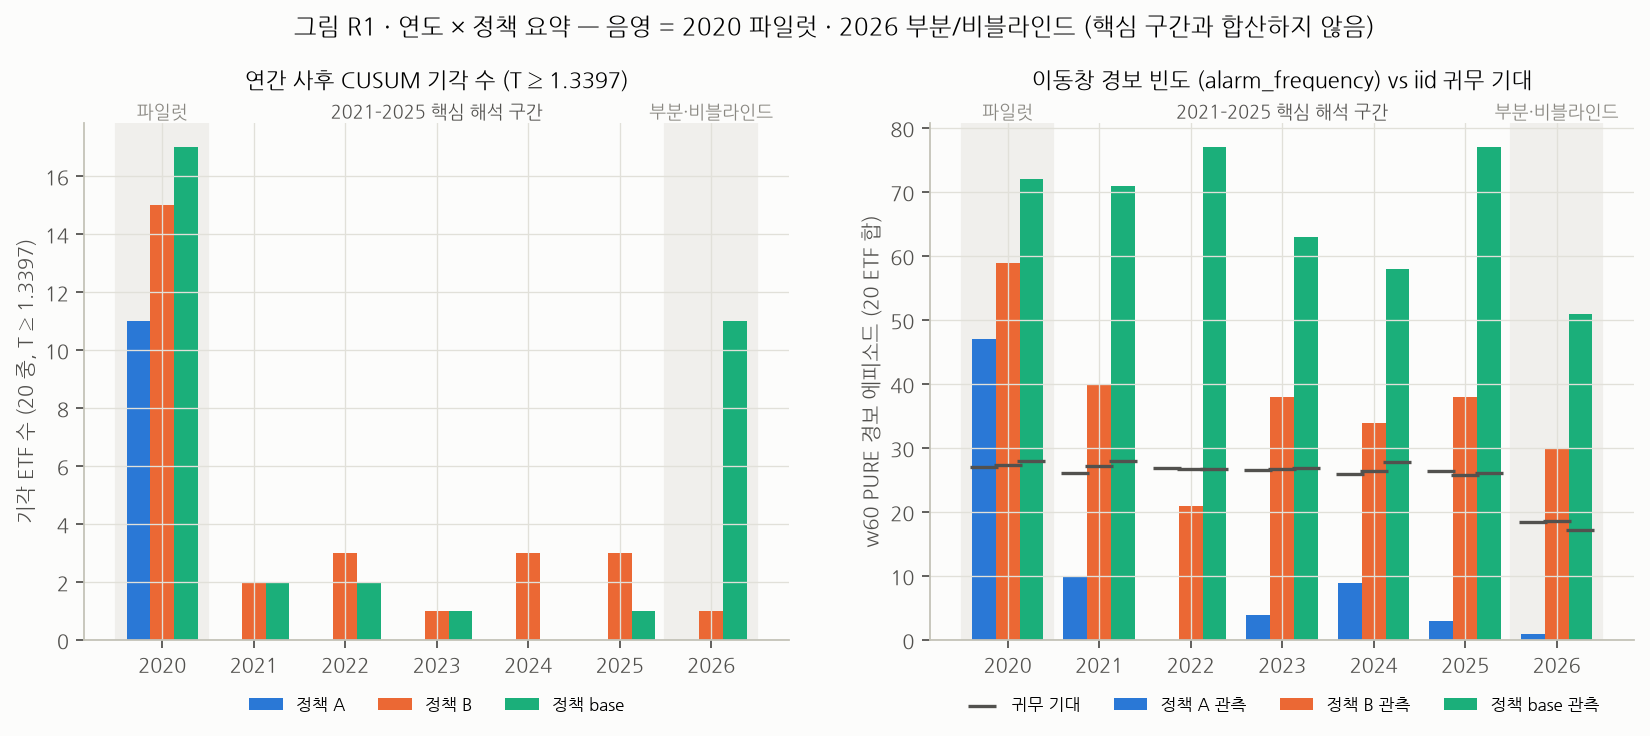

In [12]:
# 연도 목록
YEARS = list(range(2020, 2027))
# 정책 색 (t12_figures 팔레트와 같음)
COL = figs.COL
# 그림 두 칸
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
# 막대 폭
bw = 0.26
# 정책마다 막대
for k, pol in enumerate(("A", "B", "base")):
    # 그 정책의 연도별 행
    s = sy[sy.policy == pol].set_index("year").loc[YEARS]
    # 왼쪽: 1.3397 기각 수
    axes[0].bar(np.arange(len(YEARS)) + (k - 1) * bw, s.n_reject_asym, width=bw, color=COL[pol], label=f"정책 {pol}")
    # 오른쪽: 관측 경보 에피소드
    axes[1].bar(np.arange(len(YEARS)) + (k - 1) * bw, s.w60_pure_episodes_total, width=bw, color=COL[pol], label=f"정책 {pol} 관측")
    # 오른쪽: 귀무 기대 (가로 눈금)
    axes[1].scatter(np.arange(len(YEARS)) + (k - 1) * bw, s.w60_null_expected_total, marker="_", s=160, color="#52514e", zorder=3, label="귀무 기대" if k == 0 else None)
# 두 그림 공통 꾸밈
for ax in axes:
    # 2020 파일럿 구간 음영
    ax.axvspan(-0.5, 0.5, color="#f0efec", zorder=0)
    # 2026 부분·비블라인드 구간 음영
    ax.axvspan(len(YEARS) - 1.5, len(YEARS) - 0.5, color="#f0efec", zorder=0)
    # 구간 라벨: 파일럿
    ax.text(0, 1.01, "파일럿", transform=ax.get_xaxis_transform(), ha="center", fontsize=8, color="#898781")
    # 구간 라벨: 핵심
    ax.text(3, 1.01, "2021–2025 핵심 해석 구간", transform=ax.get_xaxis_transform(), ha="center", fontsize=8, color="#52514e")
    # 구간 라벨: 부분·비블라인드
    ax.text(len(YEARS) - 1, 1.01, "부분·비블라인드", transform=ax.get_xaxis_transform(), ha="center", fontsize=8, color="#898781")
    # x 눈금 = 연도
    ax.set_xticks(range(len(YEARS)), [str(y) for y in YEARS])
    # 범례 (그림 아래, 막대를 가리지 않게)
    ax.legend(frameon=False, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
# 왼쪽 축 이름
axes[0].set_ylabel("기각 ETF 수 (20 중, T ≥ 1.3397)")
# 왼쪽 제목
axes[0].set_title("연간 사후 CUSUM 기각 수 (T ≥ 1.3397)", pad=16)
# 오른쪽 축 이름
axes[1].set_ylabel("w60 PURE 경보 에피소드 (20 ETF 합)")
# 오른쪽 제목
axes[1].set_title("이동창 경보 빈도 (alarm_frequency) vs iid 귀무 기대", pad=16)
# 전체 제목
fig.suptitle("그림 R1 · 연도 × 정책 요약 — 음영 = 2020 파일럿 · 2026 부분/비블라인드 (핵심 구간과 합산하지 않음)", y=1.04)
# 저장 경로
r1 = FIG_NB / "R1_year_policy_rejections.png"
# 메타데이터 없이 저장 (바이트 재현)
fig.savefig(r1, bbox_inches="tight", metadata={"Software": None})
# 그림 닫기 (Agg 백엔드)
plt.close(fig)
# 노트북에 표시
display(Image(filename=str(r1)))

**해석 (그림 R1, 위 표)**

- **정책 A**: 2021–2025 핵심 100 ETF-연도에서 1.3397 기각 **0건**이고, w60 경보 에피소드는 귀무 기대보다 훨씬 적다 (26 vs 약 132).
  A 의 lag 입력은 직전 5일 관측 proxy 라서 분산 변화를 즉시 따라간다. 그 결과 잔차 제곱이 iid 보다도 평탄해져, 이 설정의 CUSUM 은
  변화를 거의 기각하지 못한다. 이것은 "변화가 없었다" 는 뜻이 아니라 **검정력이 낮은 설정**이라는 뜻이다.
  **A 의 비기각을 안정성의 증거로 쓰지 않는다** (파이프라인 분산 ×2 변화의 검정력 0.085 — 10절 합성).
- **정책 B** (재귀 예측): 핵심 기각 12건, 경보는 귀무 기대의 약 1.3 배다. **base** (60일 표본분산): 핵심 기각 6건, 경보는 귀무 기대의 약 2.6 배다.
  base 의 높은 경보 빈도는 60일 표준화가 변동성 군집을 남기기 때문으로 해석된다. 합성 검출기 수준에서도 잔차에 GARCH 군집이 있으면
  구조변화가 없어도 w60 연중 경보 확률이 약 0.99 였다 (10절).
  **경보 빈도가 귀무보다 높다는 사실이 실제 국면 변화를 뜻하지는 않는다.** base 의 기각은 모형화되지 않은 변동성 군집과 구별되지 않는다
  (군집 귀무 size 0.39–0.58 — A 감사 산출물 인용: `docs/annual_assurance/ANNUAL_SCIENTIFIC_AUDIT.md`, A 브랜치 `6d074eb` Q6). 정책 간 비교는 **같은 숫자 임계값(1.3397) 아래의 비교일 뿐**이다. 정책마다 귀무 분포가 다르므로 기각 수의 크기를 검정력이나 성능으로 비교하지 않는다.
- 기각 수 "20 중 k" 는 독립 시행이 아니다 (11절 R-7). 비율·유의확률로 읽지 않는다.
- **2020 파일럿**에서는 세 정책 모두 기각이 많다 (A 11 · B 15 · base 17). 그러나 학습 이력이 2019 한 해뿐이고 2020-03 급변 국면이
  포함돼 있어, 핵심 연도와 같은 무게로 읽지 않는다. **2026**의 base 11건은 부분 연도이면서 이미 알려진 고변동 국면이라
  사후 서술일 뿐이다. 블라인드 검증이 아니다. **2020 과 2026 의 기각 수 차이를 시장 구조 차이로 귀속하지 않는다** (11절 R-8).

## 8. 그림 (t12_figures 재사용) — 그림마다 해석

모든 그림은 위에서 재생성한 결과표(`RES_NB`)와 이 run 의 일별 캐시(`outputs/t12/work/<run_id>/<ticker>/daily.csv.gz`)로만 그린다.
그림 함수는 `scripts/t12_figures.py` 의 것을 그대로 쓴다. 각 그림의 원천 표 sha256 은 `figure_manifest.csv` 에 남는다.

In [13]:
# ETF 이름 사전 (reference_close_sha256.csv)
NM = figs.names()
# 이 run 의 일별 캐시 폴더
WORK_RUN = WORK_ROOT / RUN_ID
# 그림 1: fold 타임라인
figs.fig_timeline(FIG_NB, RES_NB)
# 그림 2: RV 히트맵
figs.fig_rv_heat(T, FIG_NB, RES_NB, NM)
# 그림 3: 연간 사후 T 히트맵
figs.fig_posthoc(T, FIG_NB, RES_NB, NM)
# 그림 4: 연도 경계 연결 예시 (069500)
figs.fig_boundary_example(T, WORK_RUN, FIG_NB, RES_NB)
# 그림 5: 경보 에피소드 vs 귀무
figs.fig_episodes(T, FIG_NB, RES_NB, NM)
# 그림 6: 보정 방법별 임계값
figs.fig_calibration(T, FIG_NB, RES_NB)
# 그림 7: 정책 간 일치도
figs.fig_policy_pairs(T, FIG_NB, RES_NB, NM)
# 그림 8: RV 변화 vs T
figs.fig_rv_vs_T(T, FIG_NB, RES_NB)
# 그림 9: 합성 Size/Power
figs.fig_synthetic(T, FIG_NB, RES_NB)
# 그림 10: M·N 진단
figs.fig_M_N(T, FIG_NB, RES_NB, NM)
# 그림 11: 학습 이력 대조
figs.fig_H(T, FIG_NB, RES_NB)
# 그림 12: 다축 profile
figs.fig_profile(T, FIG_NB, RES_NB, NM)
# ETF 별 요약 그림 20장
for tk in figs.order(T):
    # ETF 한 종목 그림
    figs.fig_etf(T, WORK_RUN, FIG_NB, RES_NB, tk, NM)
# 그림 manifest 저장
pd.DataFrame(figs.MANIFEST).to_csv(FIG_NB / "figure_manifest.csv", index=False, lineterminator="\n")
# 생성 수 출력
print(f"그림 {len(figs.MANIFEST)}장 → {FIG_NB.relative_to(ROOT)}")
# 커밋된 그림 폴더 (seq_golden 결과로 그린 것)
FIG_REF = ROOT / "research" / "t12_annual_expanding_v2" / "figures"
# PNG 바이트 비교 (그림은 결과가 아니므로 assert 하지 않고 보고만 한다 — 폰트·matplotlib 버전에 따라 달라질 수 있음)
png_same = [p.name for p in sorted(FIG_REF.glob("*.png")) if (FIG_NB / p.name).exists() and (FIG_NB / p.name).read_bytes() == p.read_bytes()]
# 비교 결과 출력
print(f"커밋된 그림과 PNG 바이트 동일: {len(png_same)} / {len(list(FIG_REF.glob('*.png')))}")
# 본문이 인용하는 집계값 (재생성본, 커밋본과 바이트 동일 확인됨)
AGG = pd.read_csv(RES_NB / "aggregates.csv").set_index("name")["value"]


# 그림 표시 도우미
def show_png(name):
    # 저장된 PNG 를 표시
    display(Image(filename=str(FIG_NB / f"{name}.png")))

그림 32장 → outputs/t12/notebook/b_nb_20261016T163946/figures
커밋된 그림과 PNG 바이트 동일: 32 / 32


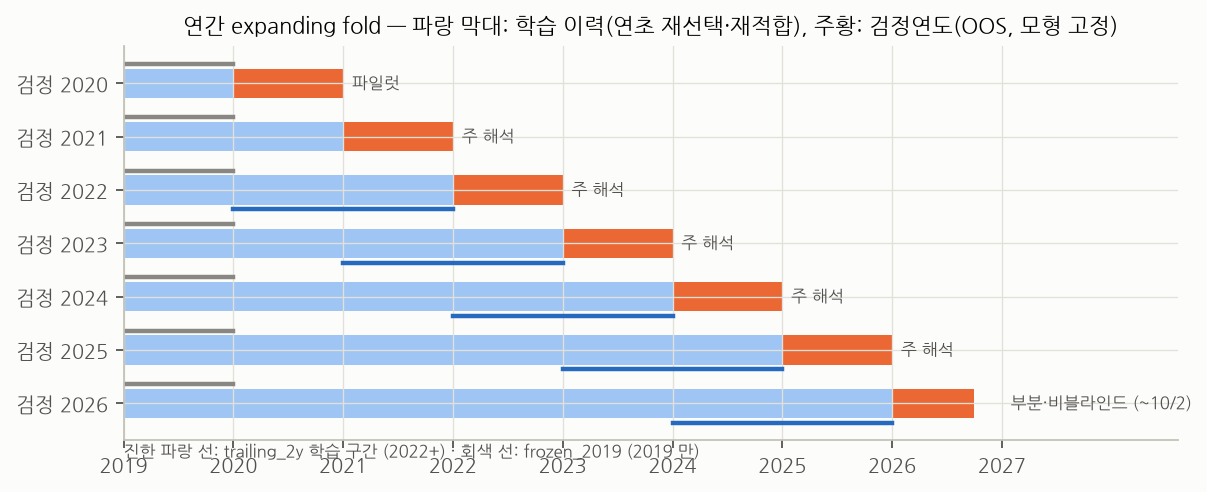

In [14]:
# 그림 1 — 연간 expanding fold 구조
show_png("F01_fold_timeline")

**해석 (그림 1)** — 파랑 = 학습 이력(연초 재선택·재적합), 주황 = 검정연도(모형 고정). 매년 학습이 한 해씩 늘어나므로
연도 간 결과에는 "학습 표본 크기" 와 "그 해의 시장" 이 섞여 있다. H 축(그림 11)이 이 둘을 같은 연도 안에서 부분적으로 분리한다.
2020 행(파일럿)은 학습 1년, 2026 행은 10/2 까지의 부분 연도다.

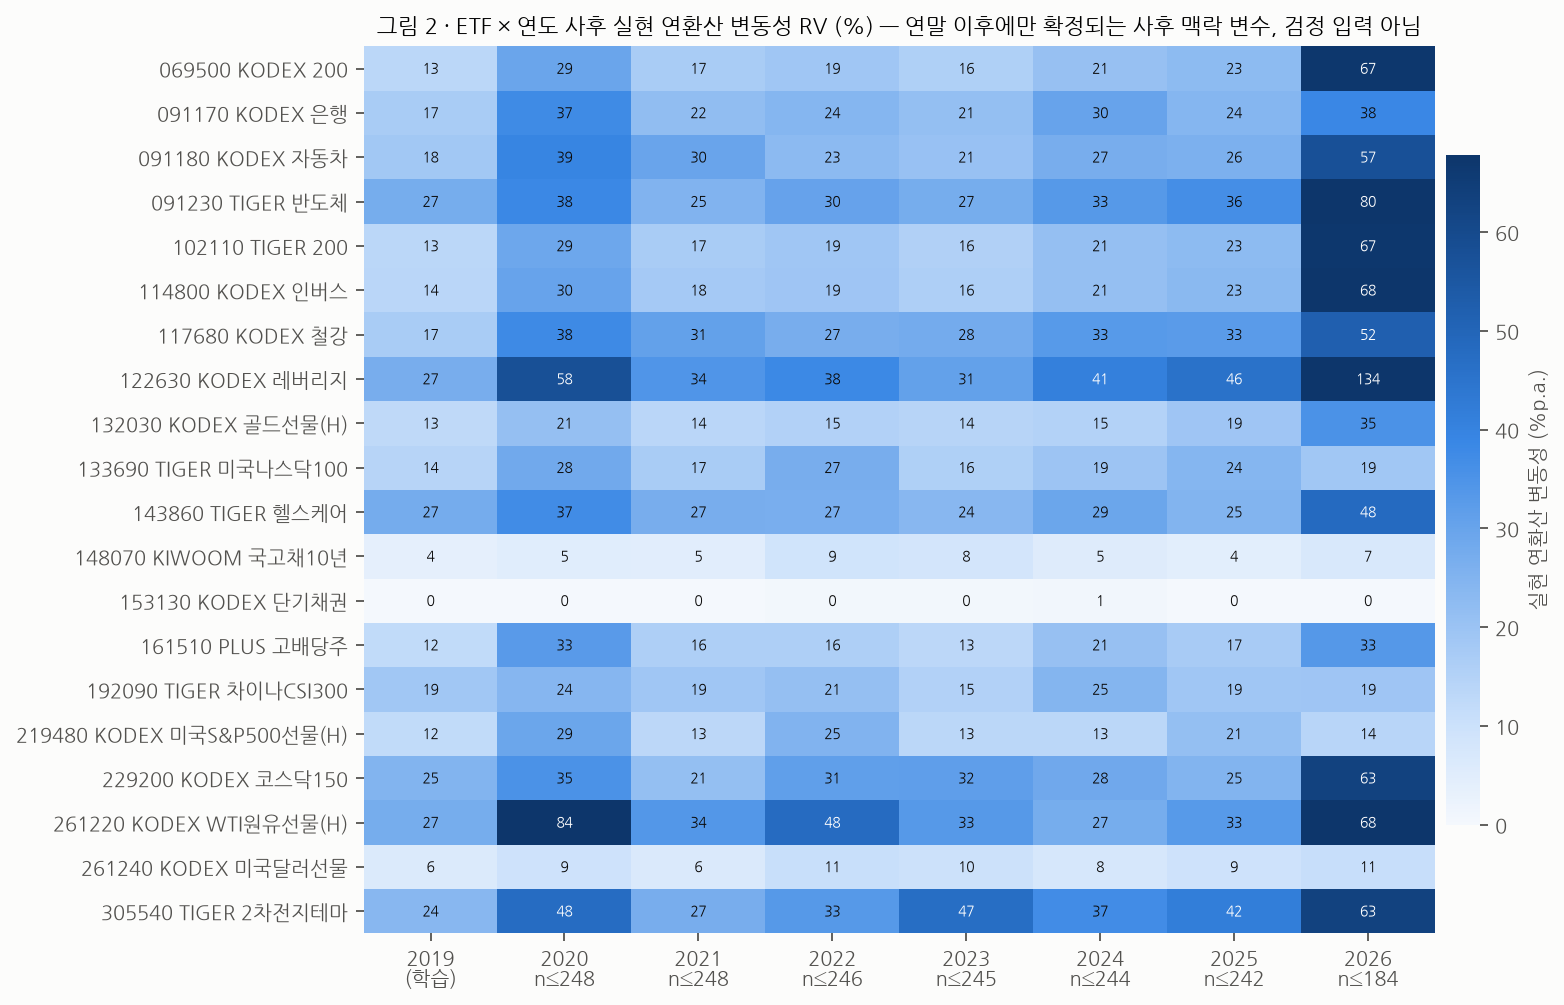

In [15]:
# 그림 2 — ETF × 연도 사후 실현 변동성
show_png("F02_rv_heatmap")

**해석 (그림 2)** — RV 는 연말 이후에만 확정되는 **사후 맥락 변수**다. 검정 입력이 아니고 원인 변수도 아니다 (L10).
2020 열(파일럿)과 2026 열(부분·비블라인드)은 핵심 구간과 성격이 다르다. 2026 은 RV 중앙값이 약 50 %p.a. 로 가장 높지만,
부분 연도이고 이미 알려진 국면이다. ETF 별로는 2차전지테마(305540)·레버리지(122630)·WTI원유(261220) 행이 전 기간 높다.

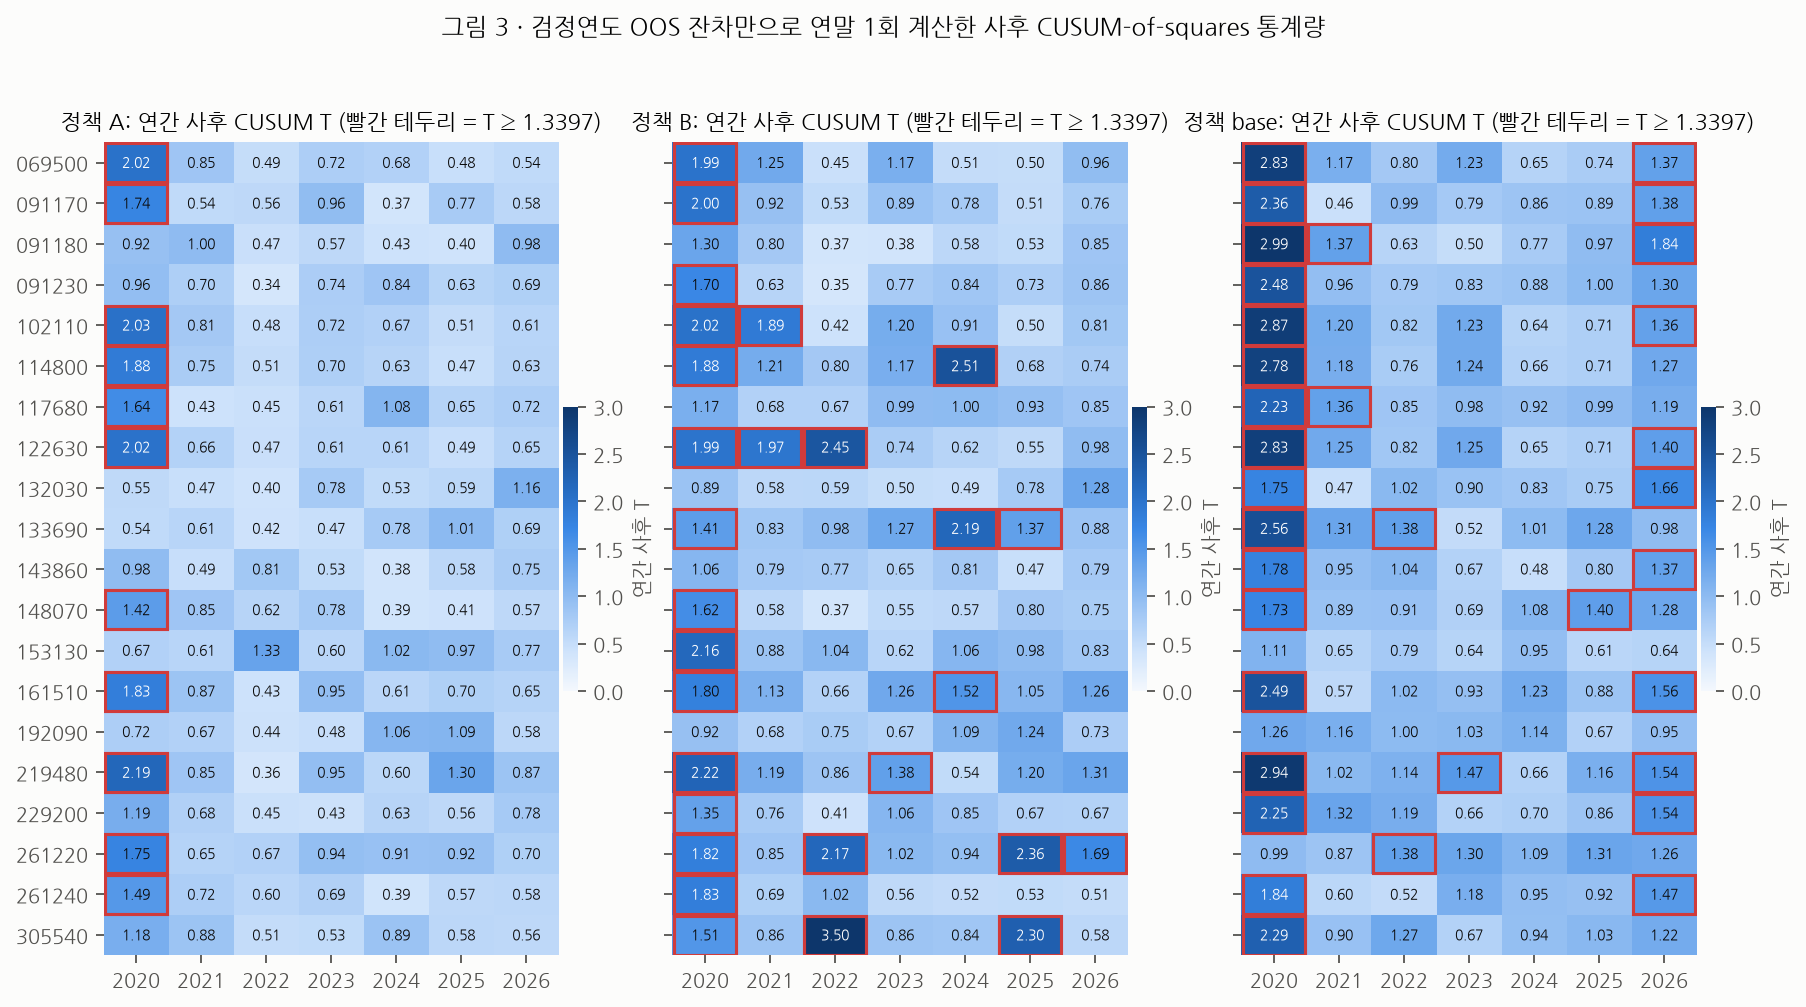

In [16]:
# 그림 3 — 연간 사후 T 히트맵 (정책별)
show_png("F03_posthoc_T_heatmap")

**해석 (그림 3)** — 빨간 테두리는 $T \ge 1.3397$ (원문 표기 임계값 기각; 열 `asymptotic`)이다. 정책 A 는 2020 열(파일럿)을 빼면 테두리가 없다.
B 의 기각은 2020 열(15건)에, base 의 기각은 2020 열(17건)과 2026 열(11건, 부분·비블라인드)에 몰려 있다.
핵심 2021–2025 에서는 B 12 · base 6 건이 흩어져 있다.
정책마다 같은 ETF-연도의 판정이 다르다는 것 자체가 결과다. **연간 기각은 "그 해 잔차 제곱 경로가 iid 귀무와 맞지 않는다"
는 진술이다. 변화의 원인이나 시점을 확정하지 않는다** ($\hat k$ 는 argmax 위치일 뿐이다).

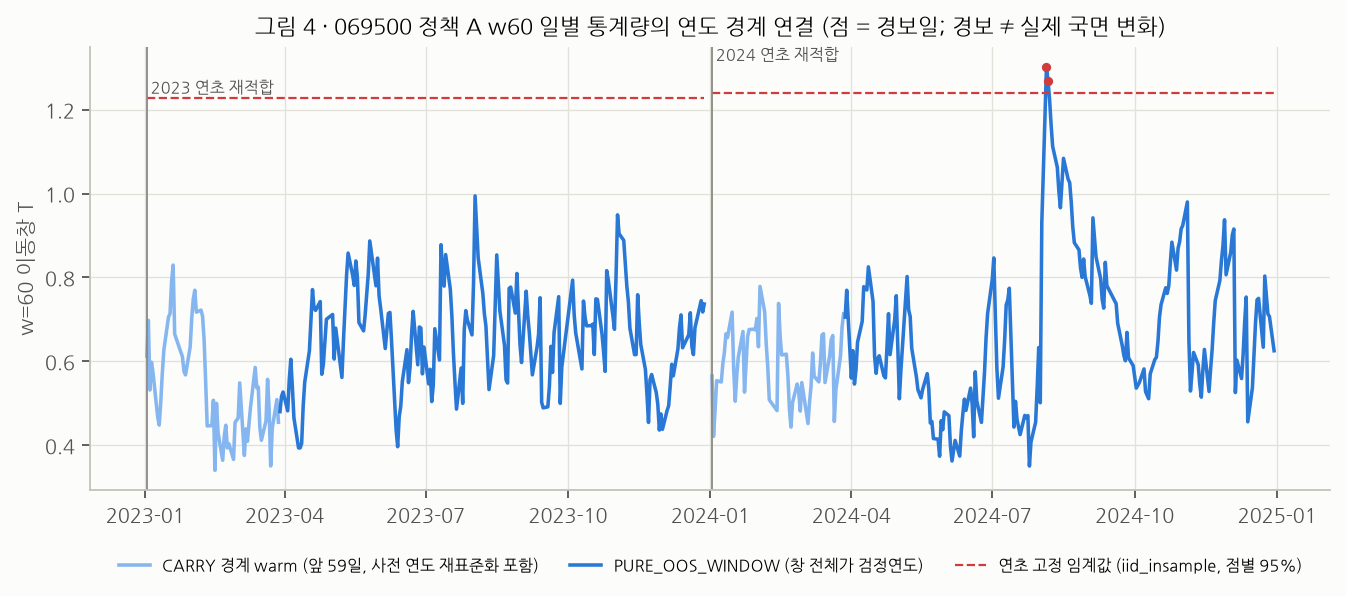

In [17]:
# 그림 4 — 연도 경계 연결 (069500, 정책 A, w60)
show_png("F04_boundary_069500")

**해석 (그림 4)** — 옅은 선은 연초 59일의 `CARRY` warm 구간이다 (창에 사전 연도 재표준화 잔차가 섞인다). 진한 선이 `PURE_OOS_WINDOW` 다.
빨간 점선은 연초에 고정한 점별 95% 임계값이고, 점은 경보일이다. 엄격한 OOS 요약은 진한 선 구간만 쓴다.
점별 95% 임계값이므로 **귀무에서도 한 해에 한 번 이상 경보가 날 확률이 높다** (합성 iid H0 에서 약 0.7, 10절).
따라서 경보 한 건을 사건으로 읽지 않는다.

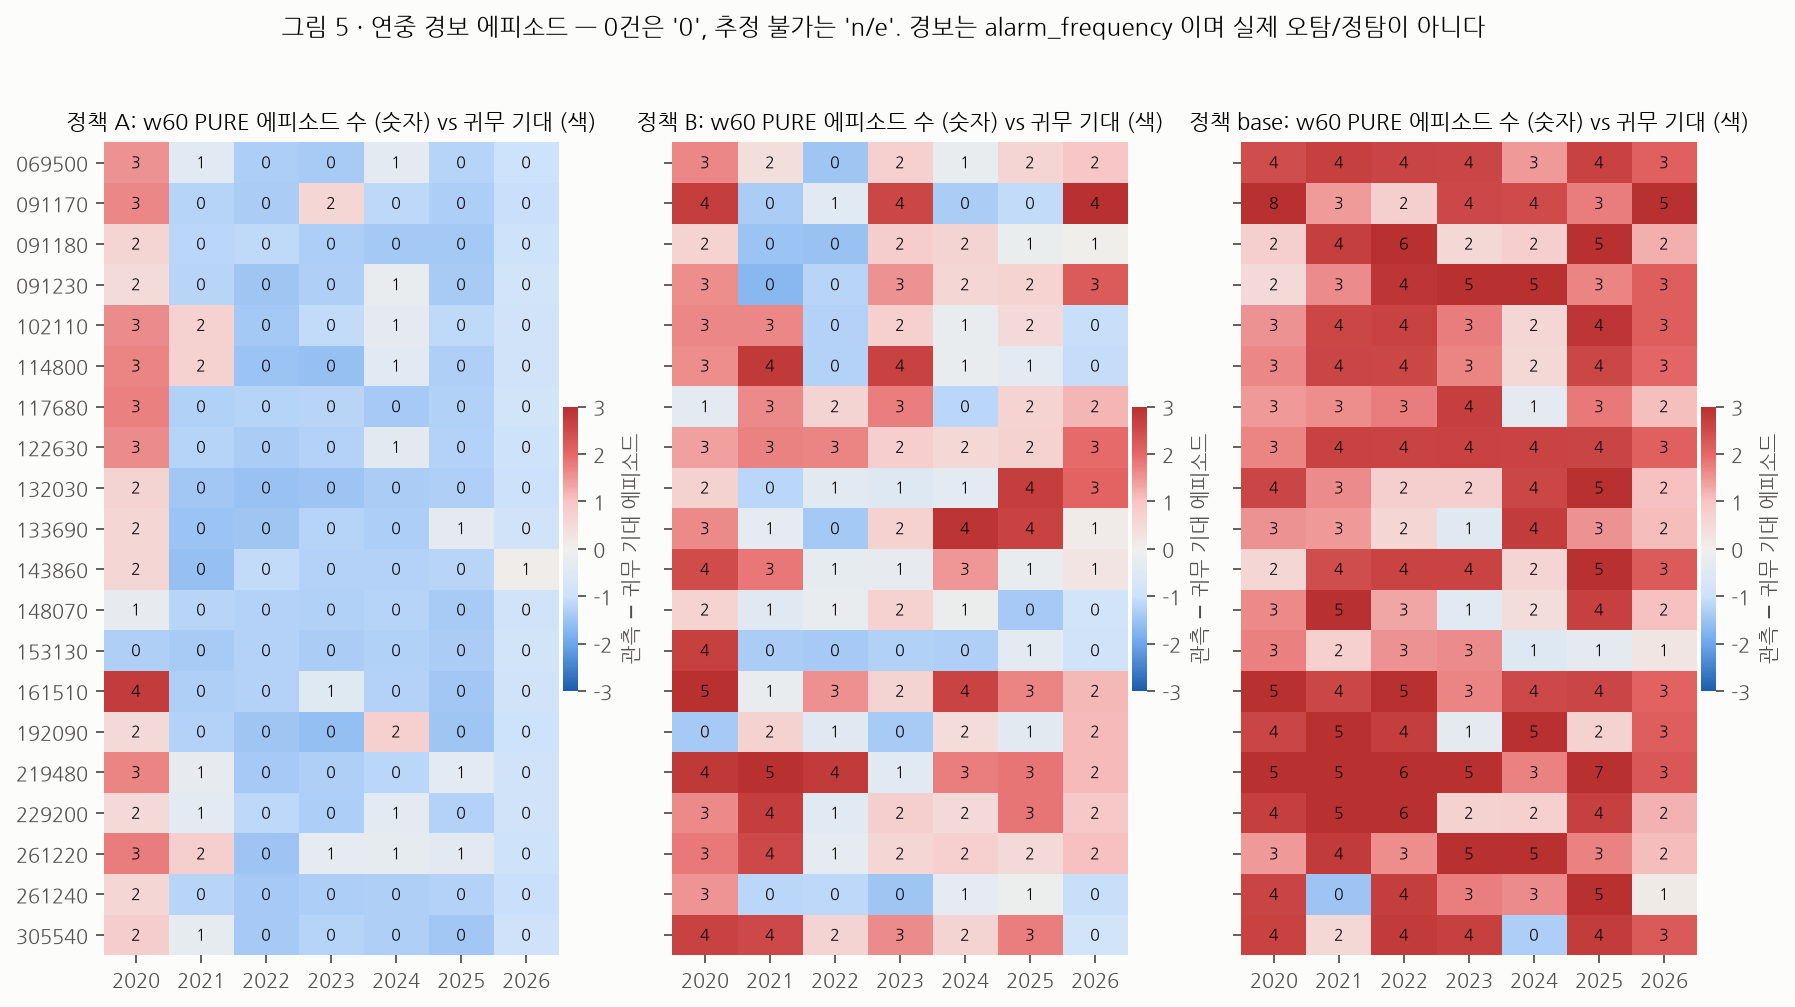

In [18]:
# 그림 5 — 경보 에피소드 vs 귀무 기대
show_png("F05_episodes_vs_null")

**해석 (그림 5)** — 숫자는 w60 PURE 에피소드 관측 수, 색은 관측 − 귀무 기대다 (파랑 = 귀무보다 적음, 빨강 = 많음).
A 는 거의 전부 파랑이다 (귀무보다 적은 경보 — 검정력 부족 신호). base 는 핵심 연도에서도 빨강이 많다.
이것은 **alarm_frequency** 이며 ground truth 가 없으므로 정탐/오탐으로 바꿔 부르지 않는다.
2020·2026 열은 핵심 연도와 별도로 읽는다.

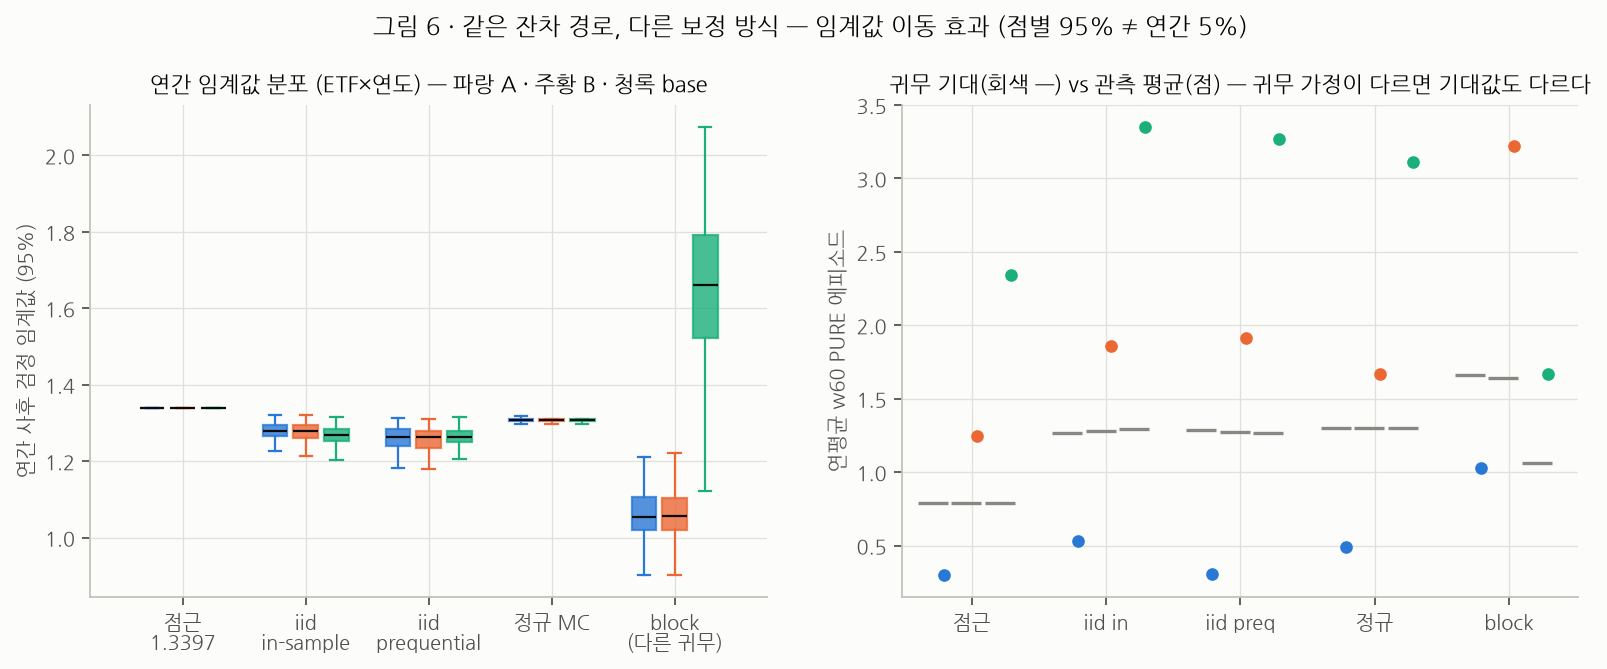

In [19]:
# 그림 6 — 보정 방법별 임계값과 기대 경보
show_png("F06_calibration_methods")

**해석 (그림 6)** — 같은 잔차 경로라도 보정 방법에 따라 임계값이 움직인다. 연간 임계값 중앙값은 원문 표기값 1.3397, 정규 MC 약 1.31,
iid in-sample 약 1.27–1.28 이다. block 부트스트랩은 단기 의존을 보존하는 **다른 귀무** (`DIFFERENT_NULL_SENSITIVITY`)다.
A·B 에서는 약 1.05 로 더 낮고 base 에서는 약 1.66 으로 더 높다 — 풀의 의존 구조가 정책마다 다르기 때문이다. 기대 경보도 방법마다 다르다.
`VERDICT_FLIPS_CALIBRATION` 이 많은 이유가 여기에 있다.
판정이 보정에 민감하다는 것(`SENSITIVITY_CONFIRMED`: A 104 · B 76 · base 34 / 140)은 계산상의 사실이다. 원인을 말해 주지 않는다.

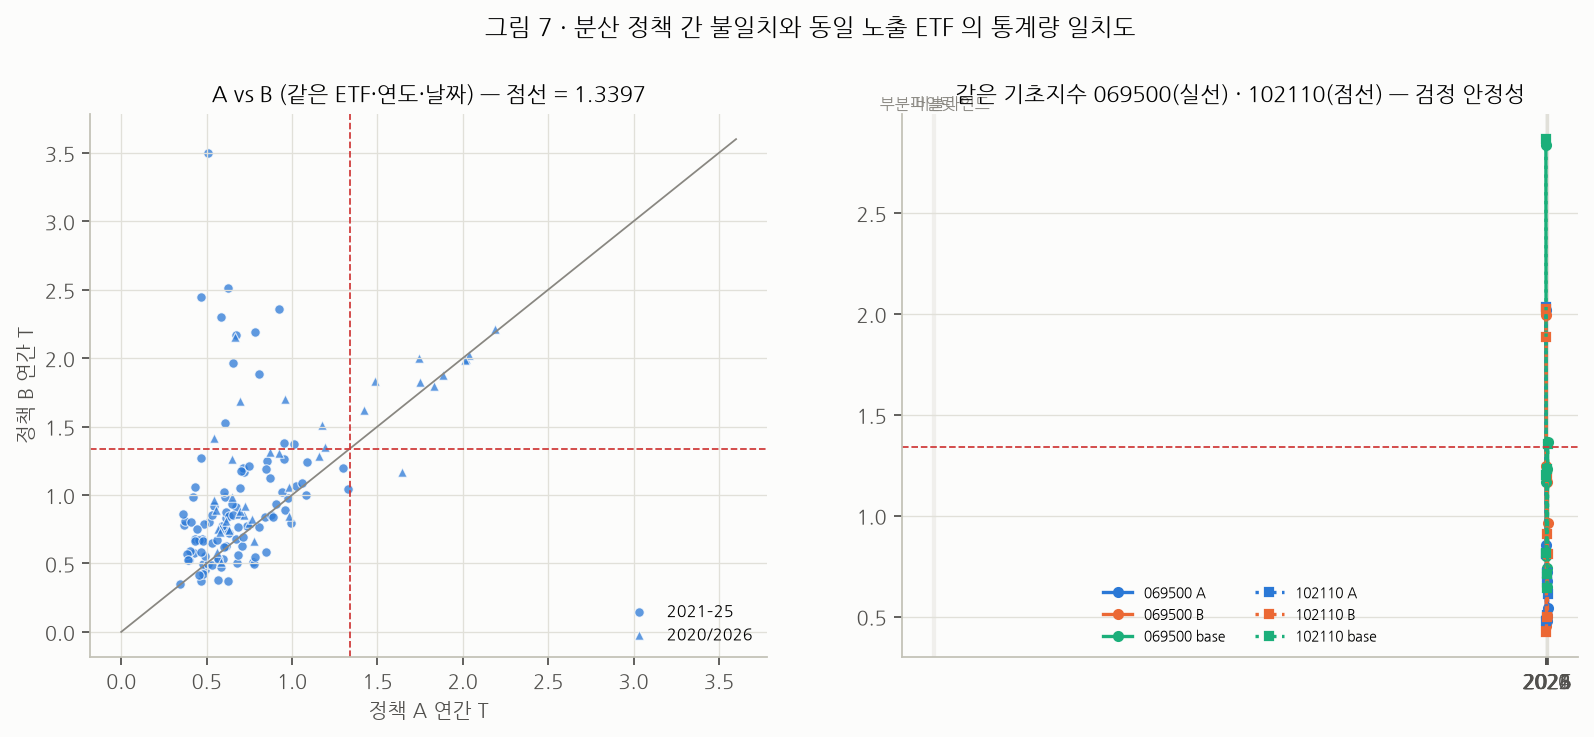

In [20]:
# 그림 7 — 정책 A vs B, 동일 노출 ETF 쌍
show_png("F07_policy_pairs")

**해석 (그림 7)** — 왼쪽: 같은 ETF·연도·날짜인데도 A 와 B 의 $T$ 가 크게 다르다. 판정은 분산 정책 선택에 강하게 의존한다.
오른쪽: 같은 KOSPI200 을 추종하는 069500·102110 의 $|T|$ 차이 최대값은 A 에서 약 0.07, B 에서 약 0.64 다. B 의 재귀 예측은
작은 입력 차이를 증폭할 수 있어 **검정 안정성이 A 보다 낮다**. 음영 = 2020 파일럿 · 2026 부분/비블라인드.

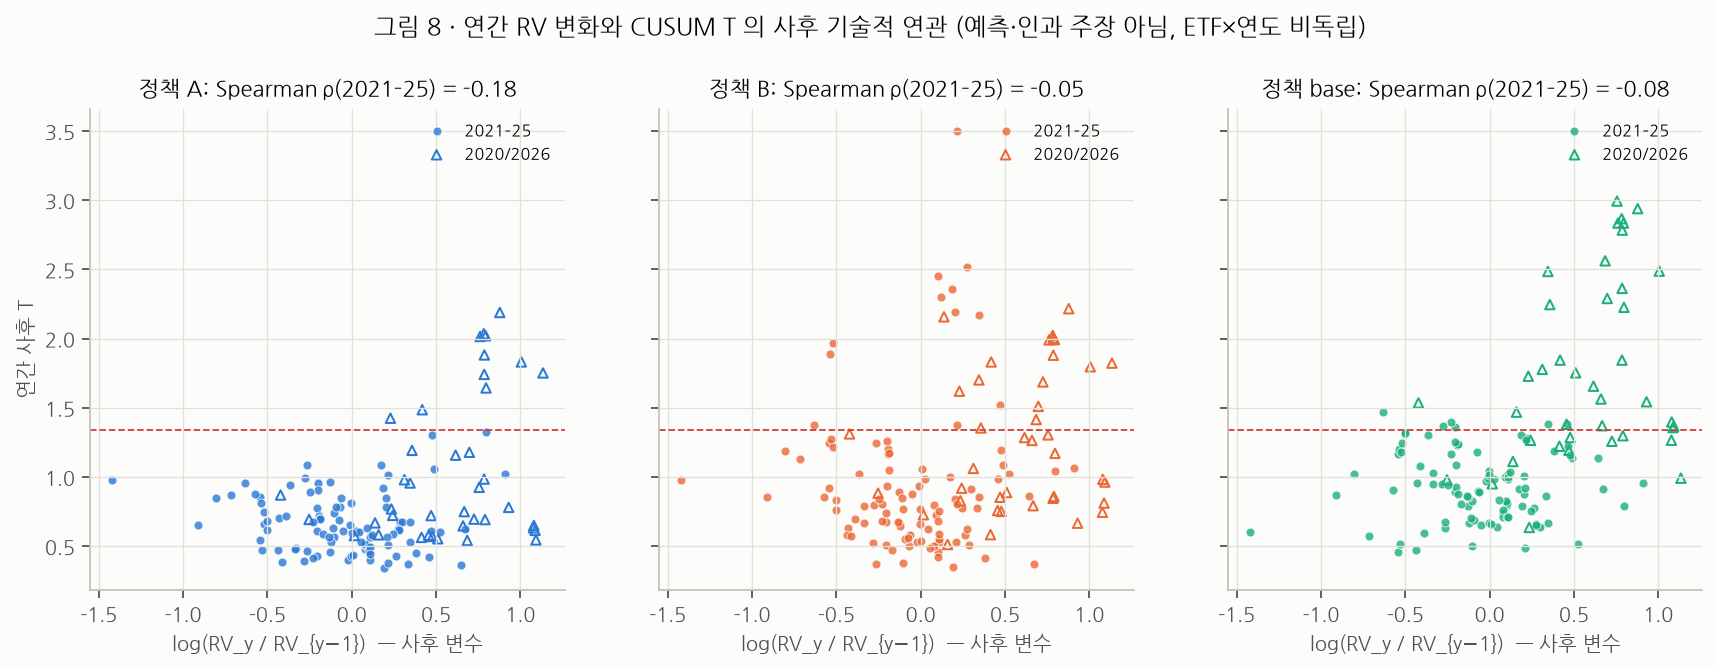

{'A': -0.183, 'B': -0.046, 'base': -0.083} (2021–25) {'A': 0.182, 'B': 0.232, 'base': 0.411} (2020–26)


In [21]:
# 그림 8 — RV 변화와 연간 T 의 사후 연관
show_png("F08_rv_vs_T")
# 핵심 구간 Spearman 값 출력 (aggregates.csv 재생성본)
print({p: round(float(AGG[f"spearman_T_rvratio_{p}_core"]), 3) for p in ("A", "B", "base")}, "(2021–25)", {p: round(float(AGG[f"spearman_T_rvratio_{p}_all"]), 3) for p in ("A", "B", "base")}, "(2020–26)")

**해석 (그림 8)** — 핵심 2021–2025 에서 $T$ 와 RV 비율의 순위상관은 세 정책 모두 0 근처다 (A −0.18 · B −0.05 · base −0.08).
2020·2026 을 포함하면 base 가 0.41 로 올라간다. 이 차이는 파일럿·부분 연도의 극단값이 만든 것으로 보이며, 핵심 구간의 관계로
일반화하지 않는다. ETF-연도는 서로 독립이 아니고 RV 는 사후 변수이므로 **예측·인과 주장이 아니다**.

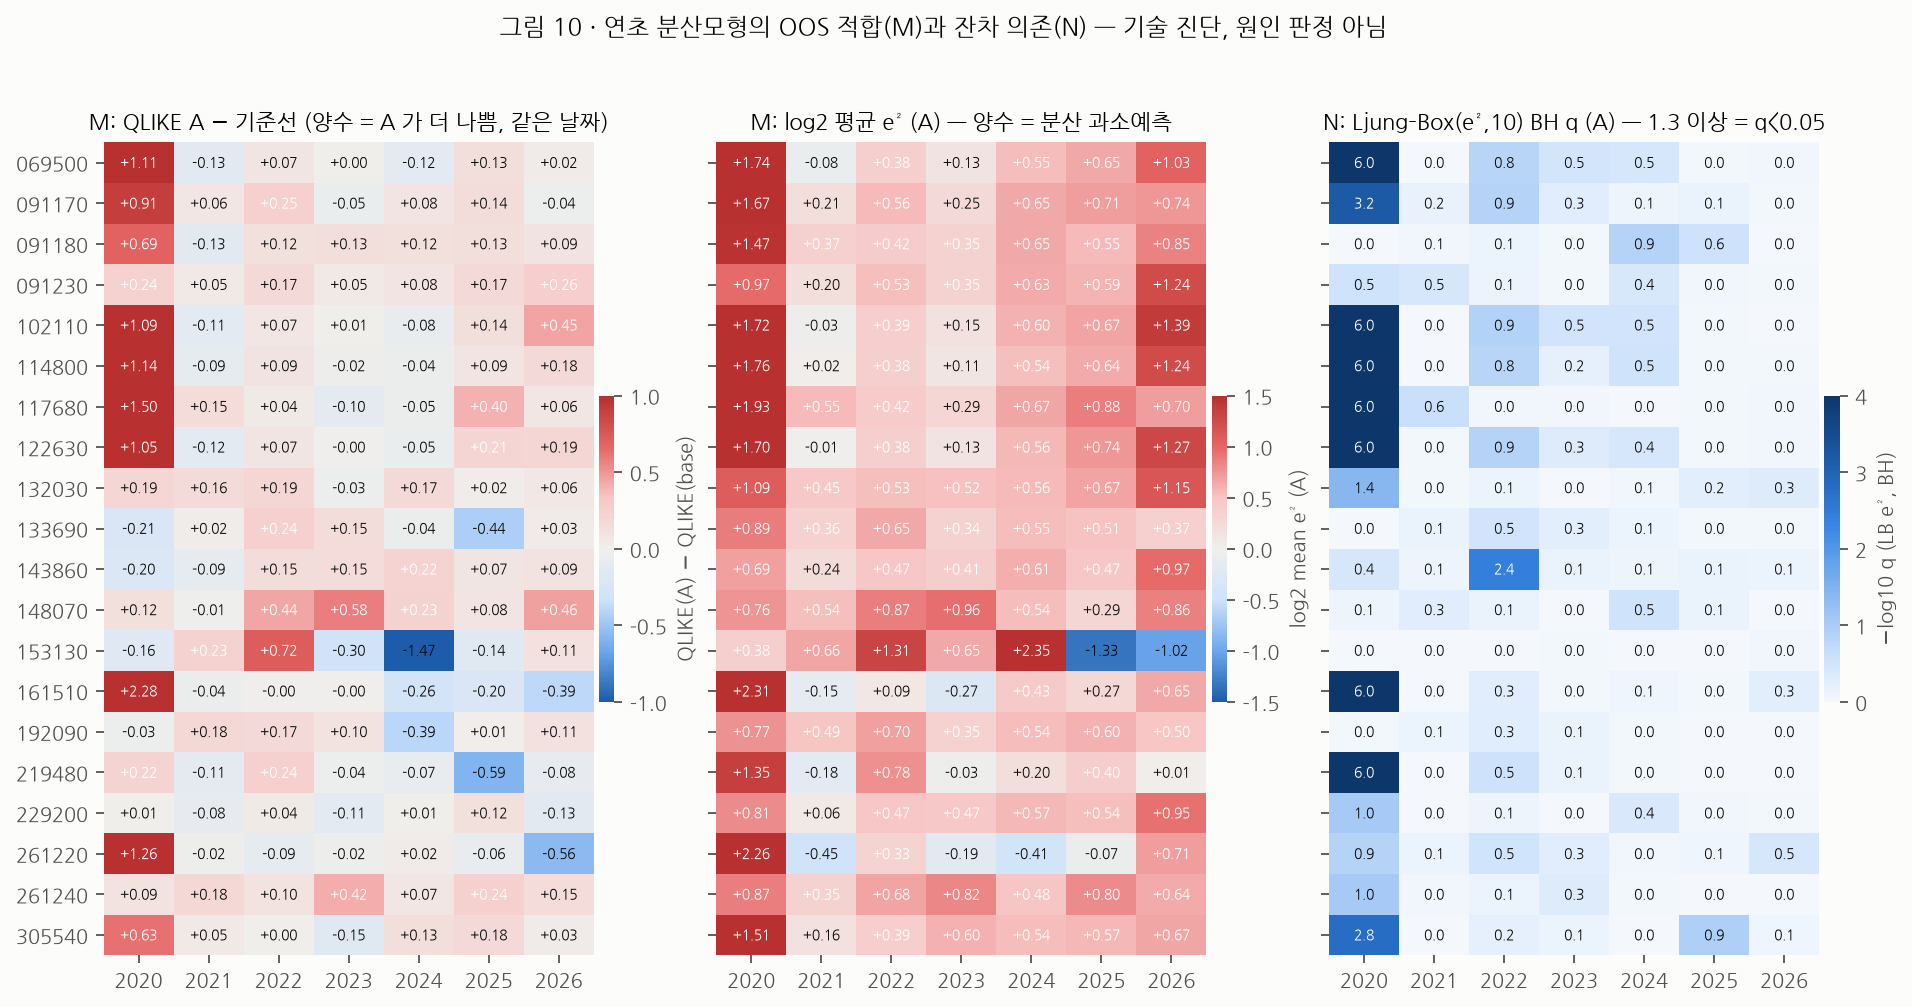

{'A': 1.386, 'B': 0.947, 'base': 1.111} · mean e² ≥ 1.5 비율: {'A': 0.28, 'B': 0.07, 'base': 0.04}


In [22]:
# 그림 10 — M(예측 적합)·N(잔차 의존) 진단
show_png("F10_M_N_heatmaps")
# 핵심 구간 평균 e² 중앙값 출력
print({p: round(float(AGG[f"core_median_mean_e2_{p}"]), 3) for p in ("A", "B", "base")}, "· mean e² ≥ 1.5 비율:", {p: round(float(AGG[f"core_share_e2_ge_1p5_{p}"]), 2) for p in ("A", "B", "base")})

**해석 (그림 10)** — 가운데 패널: A 의 평균 $e^2$ 는 핵심 구간 중앙값 약 1.39 다. ETF-연도의 28% 에서 1.5 이상이다
(분산 **과소예측** 플래그). 연초에 고정한 SVR 이 검정연도 분산 수준을 낮게 잡는 경향이 있다는 기술 진단이다.
왼쪽: 연도별 중앙값 기준 QLIKE(A) − QLIKE(base) 는 2020 +0.43, 2022·2025 약 +0.1 이고, 나머지 핵심 연도는 0 근처다 (`summary_by_year_policy.median_qlike_minus_base`). 오른쪽: Ljung–Box($e^2$) BH q 는 잔차 제곱 의존이 남은 ETF-연도를 보여 준다.
모두 **원인 판정이 아닌 기술 진단**이다. 또한 140 개 expanding 적합 중 98.6% 가 ε=0.1 (grid 하한)을 골랐다 — grid 가 좁을 수 있다는 신호이며,
결과를 본 뒤 grid 를 넓히지 않았다.

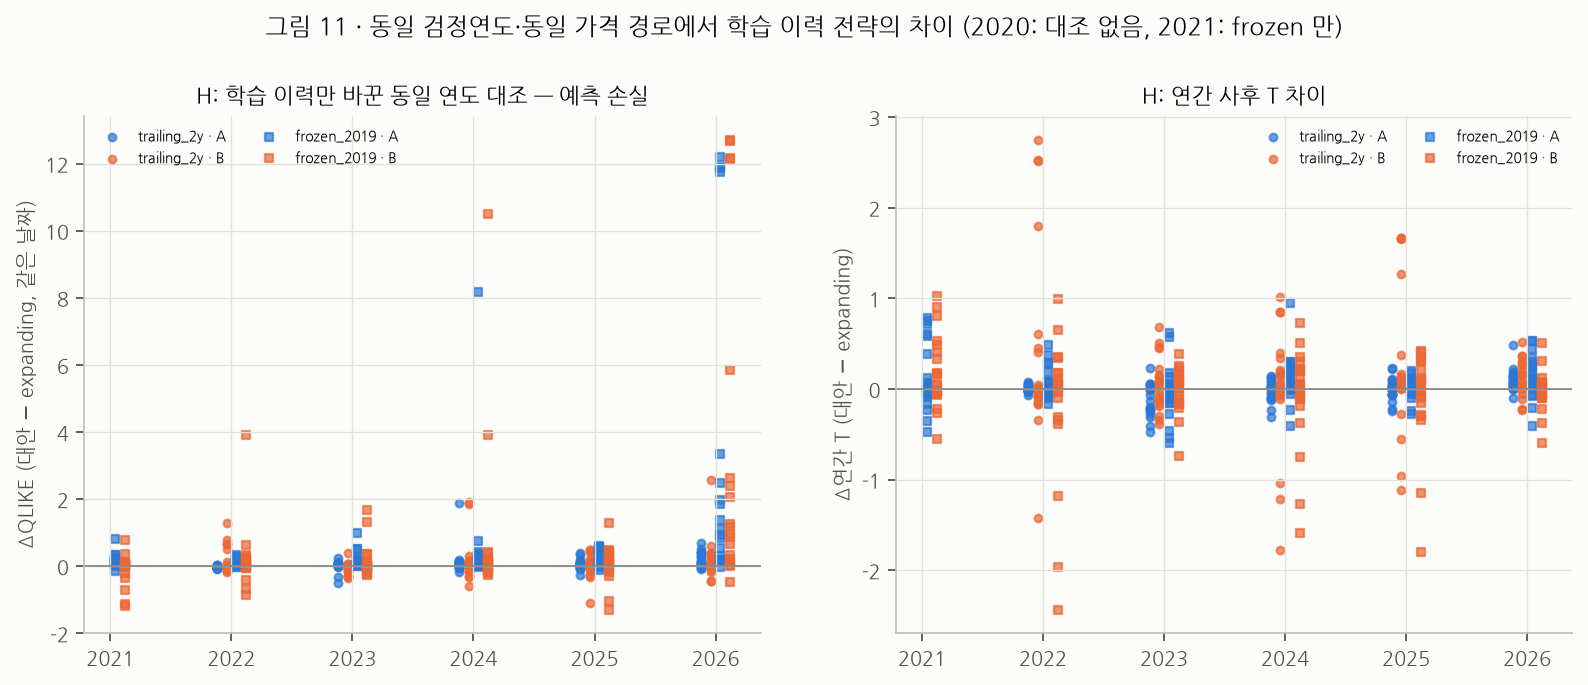

{'h_frozen_2019_A_frac_worse': 0.942, 'h_frozen_2019_A_dq_median': 0.157, 'h_trailing_2y_A_frac_worse': 0.65, 'h_verdict_diff_A': 9.0, 'h_verdict_diff_B': 46.0}


In [23]:
# 그림 11 — 학습 이력 전략 대조 (H 축)
show_png("F11_history_ablation")
# 대조 요약 출력
print({k: round(float(AGG[k]), 3) for k in ("h_frozen_2019_A_frac_worse", "h_frozen_2019_A_dq_median", "h_trailing_2y_A_frac_worse", "h_verdict_diff_A", "h_verdict_diff_B")})

**해석 (그림 11)** — 같은 검정연도·같은 날짜에서 학습 이력만 바꿨다. 정책 A 에서 `frozen_2019` 는 대조의 약 94% 에서
expanding 보다 QLIKE 가 나쁘다 (중앙값 +0.16). `trailing_2y` 는 약 65% 에서 나쁘다. 1.3397 판정이 expanding 과 달라진 대조는
A 9 / 220, B 46 / 220 이다. 즉 **B 의 판정은 학습 이력 선택에도 민감하다**. 2020 은 대조가 없고 2021 은 frozen 만 있다.
2026 의 큰 차이는 부분·비블라인드 연도의 값이다.

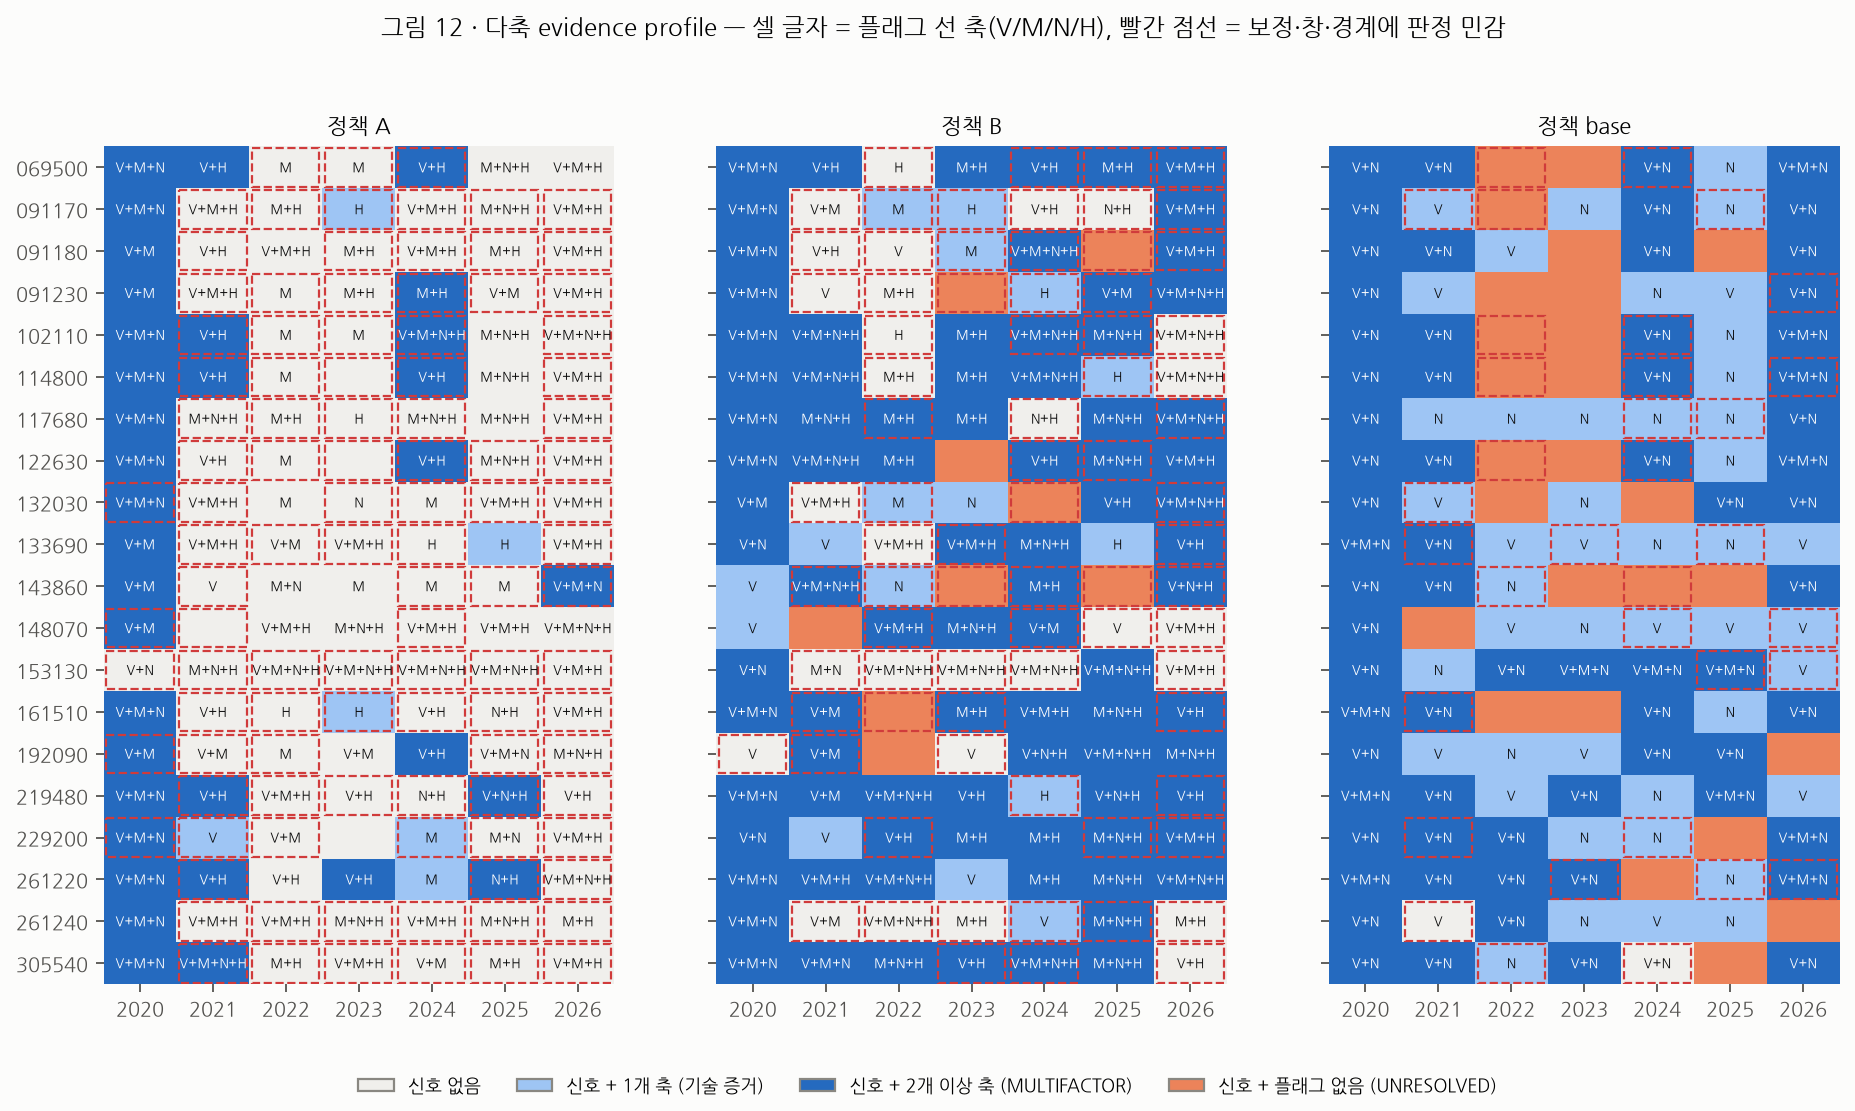

,신호 셀,w60 단독,연간 기각 포함
policy,,,
A,41,30,11
B,111,83,28
base,138,104,34
합계,290,217,73


귀무 P(연중 w60 PURE 에피소드 ≥1) 셀 평균 = 0.684 (범위 0.49–0.81)


In [24]:
# 그림 12 — 다축 evidence profile
show_png("F12_profile_status")
# 재생성한 profile 표 (신호 게이트 분해용)
prof = T["diagnostic_profile"]
# 신호 셀 = 연간 1.3397 기각 OR w60 PURE 에피소드 ≥1 (profile.py 사전 고정 규칙)
sig = prof[prof.signal_present.astype(bool)]
# 연간 기각 없이 w60 에피소드만으로 켜진 셀
w60_only = sig[~sig.annual_reject_asym.astype(bool)]
# 정책별 (신호, w60 단독, 연간 기각 포함) 셀 수
gate = pd.DataFrame({"신호 셀": sig.groupby("policy").size(), "w60 단독": w60_only.groupby("policy").size()}).loc[["A", "B", "base"]]
# 연간 기각으로 켜진 셀 수
gate["연간 기각 포함"] = gate["신호 셀"] - gate["w60 단독"]
# 합계 행 추가
gate.loc["합계"] = gate.sum()
# 표 표시
display(gate)
# 귀무에서 w60 PURE 창이 연중 ≥1 에피소드를 낼 확률 (iid_insample, YEAR_CONTAINED, 셀 평균)
cu60 = T["annual_cusum_diagnostics"].query("window == 60 and boundary_mode == 'YEAR_CONTAINED' and calibration_method == 'iid_insample'")
# 평균 확률 출력
print(f"귀무 P(연중 w60 PURE 에피소드 ≥1) 셀 평균 = {cu60.null_prob_any_episode.mean():.3f} (범위 {cu60.null_prob_any_episode.min():.2f}–{cu60.null_prob_any_episode.max():.2f})")

**해석 (그림 12)** — 셀 글자는 사전 고정 규칙(L7)으로 플래그가 선 축(V/M/N/H)이다. 진한 파랑 `MULTIFACTOR` 는 신호가 있고 축이 2개 이상
겹친 경우다. 한 경로의 실현값만으로는 **축들을 분리할 수 없다** (`unresolved_questions`). 빨간 점선은 보정·창·경계 중 하나에서
판정이 뒤집힌 셀이다. 이 그림은 "무엇이 함께 관측됐는가" 의 기술이고, "무엇이 원인인가" 는 답하지 않는다.

**신호 게이트의 한계 (A RQ-7)** — "설명할 신호" 는 연간 1.3397 기각 **또는** w60 PURE 에피소드 ≥1 이다. 위 표처럼 신호 셀 290개
(A 41 · B 111 · base 138) 중 217개 (A 30 · B 83 · base 104) 가 연간 기각 없이 w60 에피소드만으로 켜졌다. 연간 기각으로 켜진 셀은 A 11 · B 28 · base 34 다.
그런데 귀무에서도 w60 PURE 창이 연중 한 번 이상 경보를 낼 확률이 셀 평균 약 0.68 이다 (위 출력). 따라서 `MULTIFACTOR`·`DESCRIPTIVE_EVIDENCE`·`UNRESOLVED`
라벨은 대부분 **귀무에서도 흔한 신호**에 붙어 있다. 규칙은 사전 고정이라 바꾸지 않았다. 라벨을 "설명된 변화" 로 읽지 않는다.

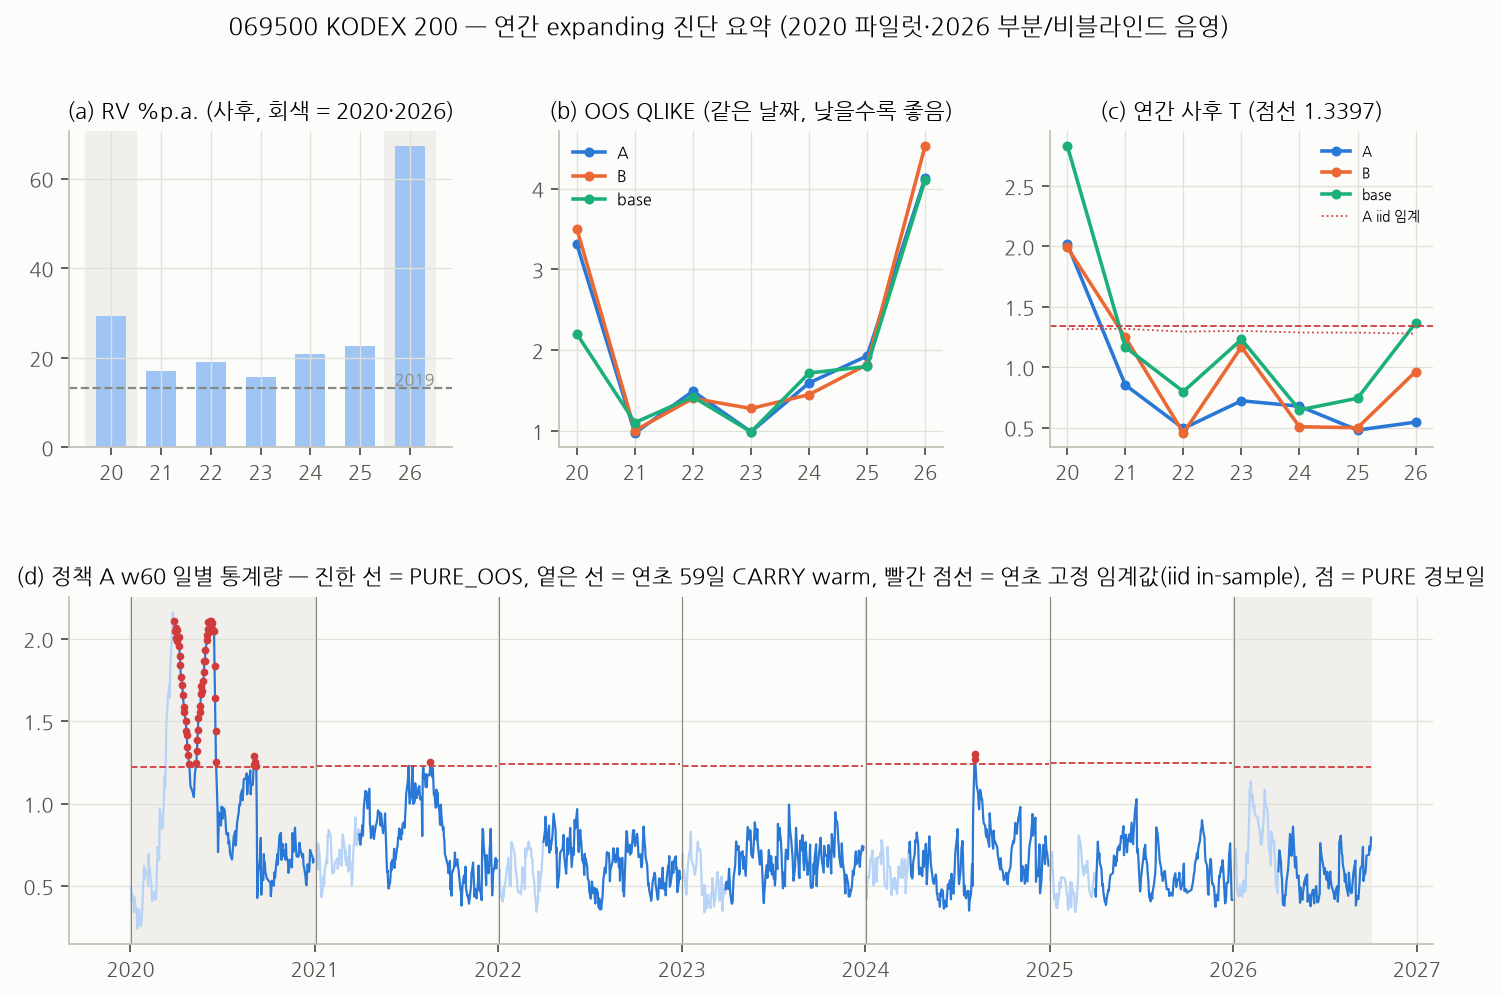

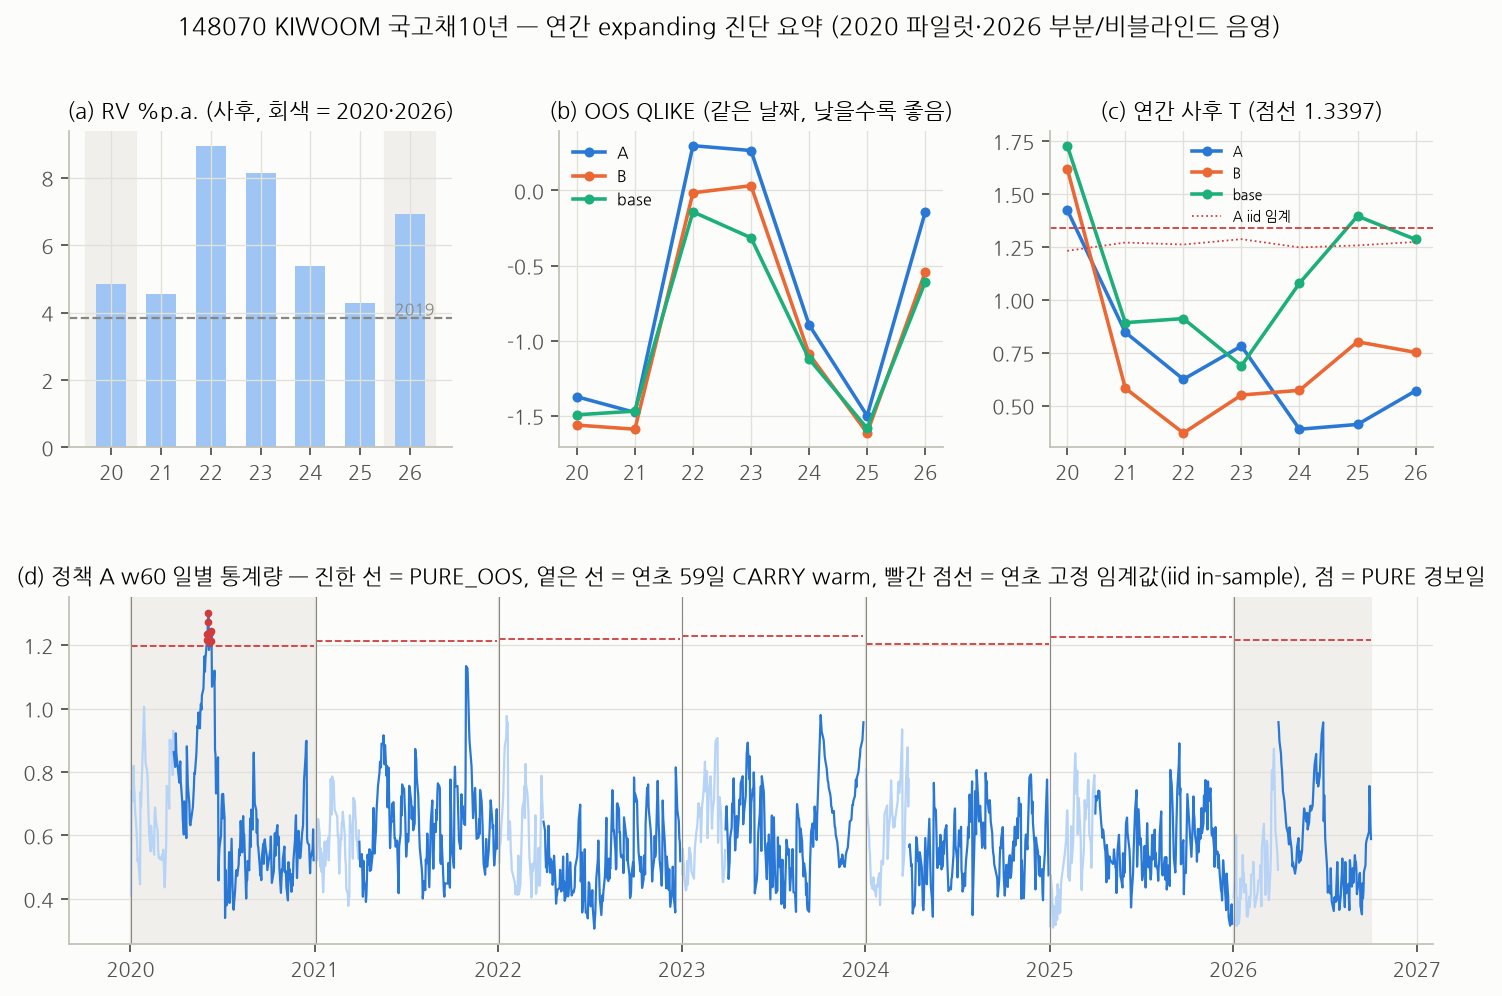

In [25]:
# ETF 별 요약 예시 — 069500 (KOSPI200) 과 148070 (국고채 10년)
for tk in ("069500", "148070"):
    # 저장된 ETF 그림 표시
    show_png(f"ETF_{tk}")

**해석 (ETF 요약 예시)** — (a) RV 막대의 회색 음영 = 2020 파일럿 · 2026 부분/비블라인드. (c) 연간 $T$ 의 점선은 1.3397, 빨간 점선은
A 의 iid 유한표본 임계값이다. (d) 일별 w60 통계량에서 진한 선만 PURE OOS 다. 나머지 18 종 그림은
`outputs/t12/notebook/<run_id>/figures/ETF_*.png` 에 있다.

## 9. T11 (70:30) 과의 관계 — 성능 비교가 아니다

| | T11 (`R2H_T11_svr_garch_cusum_etf.ipynb`) | T12 (이 노트북) |
|---|---|---|
| 분할 | ETF 마다 전체의 앞 70% 적합 (그 안 70/30) / 뒤 30% 검정 (2024-05-29 이후, 1회) | 연도마다 연초 재선택·재적합, 검정 = 그 달력연도 (7회) |
| 검정 구간 | 2024-05 ~ 2026-10 한 덩어리 (2026 국면 포함) | 2020 … 2026 각 연도 (2020 파일럿 · 2026 부분/비블라인드) |
| 임계값 | 적합 구간 잔차 iid 부트스트랩 (ETF 1개 임계값) | 연도별 사전 풀, 5 보정 방법, 점별 95% |
| 사건 정렬 | Track A·EDA 사건(P1·P4·C3·공통충격)과 정합성 검사 | 사건 정답을 쓰지 않음 (L10) |

학습 표본·검정 구간·임계값·평가 단위가 모두 다르다. 그래서 두 노트북의 기각 수·경보 수를 나란히 놓고 **"T12 가 더 낫다/못하다"
라고 말할 수 없다.** 공통으로 관찰되는 것은 정성적 패턴 하나다: 정책 A 의 경보가 iid 기준값보다 적고, base 의 경보가 많다
(두 실험 모두 사전 고정 규칙으로 얻은 기술 결과다).

**base 는 T11 과 같은 계산이다 (A RQ-11)** — T12 base 의 연간 $T$ 는 T11 `yearly_blocks` 의 base 와 같은 계산이다
(140/140 일치, 최대 상대차 4.2e-6 — A 감사 산출물 인용: `docs/annual_assurance/out/a3_t11_t12_base_check.txt`). 이 일치는 같은 식을 두 번 계산한 결과다.
**"T12 가 T11 을 재현/확인했다" 라고 쓰지 않는다.** T12 고유 결과도 아니다. 비교 불가 항목은 A `T11_T12_COMPARISON_CONTRACT.md` 의 N-1–N-8 을 따른다
(사후 검정 기각 수, `yearly_blocks` svrA, 귀무 에피소드 단위, 부트스트랩 임계값, 에피소드 합계, 정책 B 재귀, 사건 근접, 재현 서술).

## 10. 합성 검증 (G2/G5) — 저장된 결과 + 해시 검증 + 재실행 명령

- 실데이터에는 정답이 없으므로, 검정의 Size/Power 와 이동창의 **연간** 경보 확률은 합성 DGP 로만 잰다 (`SYNTHETIC_CAUSAL_KNOWN_ONLY`).
- **재실행하지 않는 것이 기본인 이유**: (1) 기록된 3회 실행(workers=4, 136.7 · 137.6 · 142.3 s)이 모두 sha256 `43de7bca9b4265d4…` 로
  동일하다. (2) 합성은 실데이터 결과표와 입력·코드 경로가 겹치지 않는다. (3) 결정성이 확인된 조건은 workers=4 뿐이다.
  순차 실행은 검증되지 않은 조건이고, 노트북 안 다중 프로세스는 spawn 피클 제약이 있다.
  그래서 6절에서 저장본의 sha256 을 assert 했다. `T12_RUN_SYNTHETIC=1` 이면 아래 셀이 CLI 를 subprocess 로 다시 돌려
  같은 sha256 이 나오는지 확인한다 (출력은 `outputs/t12/notebook/<run_id>/synthetic/`).
- 재실행 명령: `env -u VIRTUAL_ENV PYTHONPATH=$PWD/src <R2H>/.venv/bin/python scripts/run_t12_synthetic_validation.py --workers 4 --out outputs/t12/synthetic_rerun`

합성 재실행 생략 (T12_RUN_SYNTHETIC != 1) — 저장본 sha256 43de7bca9b4265d4 검증 완료 (6절)


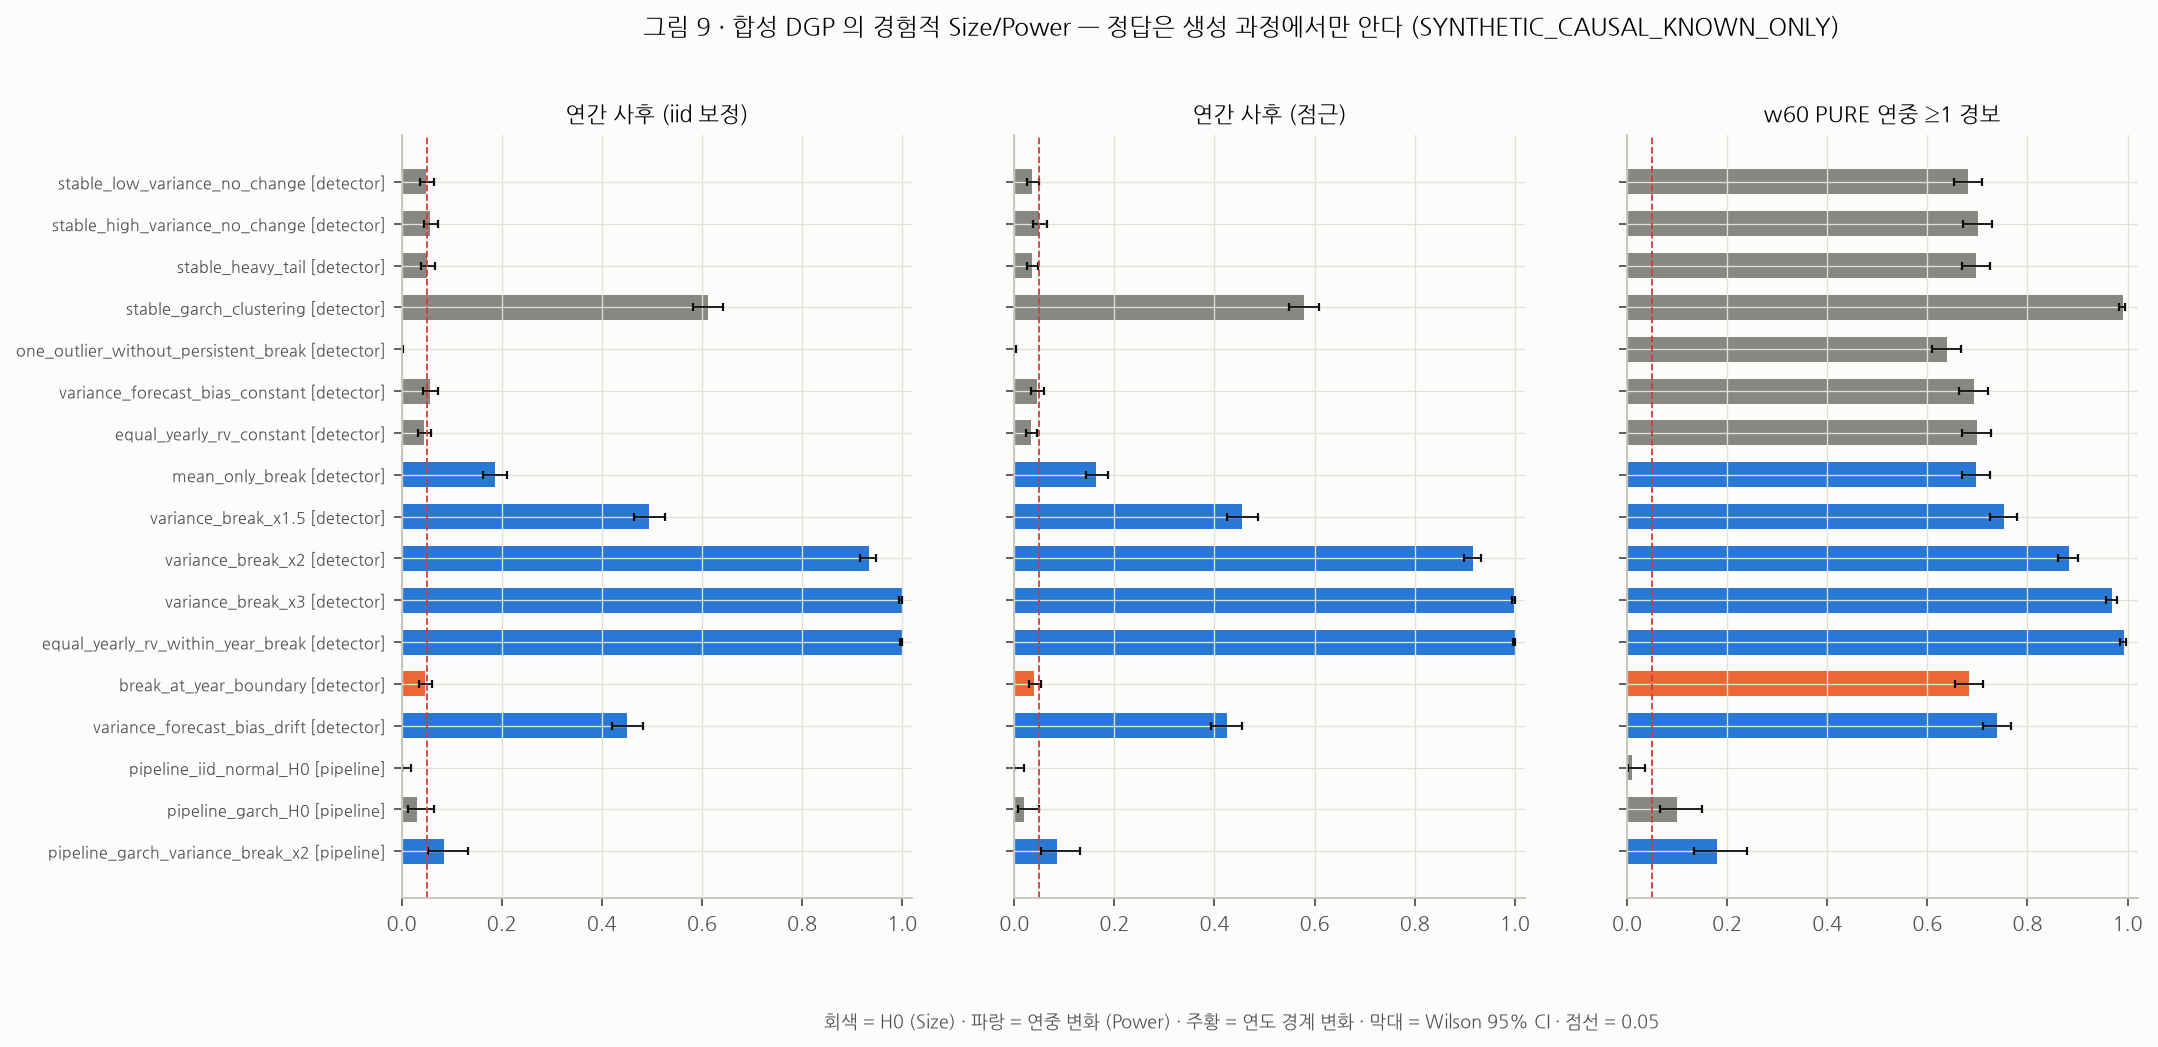

In [26]:
# 외부 프로세스 실행
import subprocess

# 재실행 여부 (기본: 하지 않음 — 저장본 해시 검증으로 대체)
RUN_SYNTHETIC = os.environ.get("T12_RUN_SYNTHETIC", "") == "1"
# 재실행 출력 폴더
SYN_OUT = NB_OUT / "synthetic"
# 재실행할 때만
if RUN_SYNTHETIC:
    # 자식 프로세스 환경: 이 저장소 src 를 import 하도록 PYTHONPATH 고정, 다른 venv 변수 제거
    env = {k: v for k, v in os.environ.items() if k not in ("VIRTUAL_ENV", "LD_LIBRARY_PATH")} | {"PYTHONPATH": str(ROOT / "src")}
    # 시작 시각
    ts = time.time()
    # CLI 그대로 실행 (출력 폴더 명시 — 기본값을 쓰지 않는다)
    subprocess.run([sys.executable, str(ROOT / "scripts" / "run_t12_synthetic_validation.py"), "--workers", "4", "--out", str(SYN_OUT)], cwd=ROOT, env=env, check=True)
    # 새 결과 해시
    new_sha = hashlib.sha256((SYN_OUT / "null_dgp_validation.csv").read_bytes()).hexdigest()
    # 결과 출력
    print(f"합성 재실행 {time.time() - ts:.0f} s · sha256 {new_sha[:16]} · 저장본과 {'동일' if new_sha == SYNTHETIC_SHA else '다름'}")
    # 저장본과 같아야 한다
    assert new_sha == SYNTHETIC_SHA
# 재실행하지 않으면 저장본 검증 결과만 알린다
else:
    # 안내 출력
    print(f"합성 재실행 생략 (T12_RUN_SYNTHETIC != 1) — 저장본 sha256 {SYNTHETIC_SHA[:16]} 검증 완료 (6절)")
# 그림 9 — 합성 DGP 의 경험적 Size/Power
show_png("F09_synthetic_size_power")

**해석 (그림 9)** — 회색 = H0 (Size), 파랑 = 연중 변화 (Power), 주황 = 연도 경계 변화. 막대 = Wilson 95% CI, 점선 = 0.05.

- **검출기 수준**(잔차를 직접 생성): 연간 사후 검정은 iid·t5 꼬리 H0 에서 Size 가 0.04–0.06 이다 (iid 보정 0.049 · 0.051).
  그러나 잔차에 **GARCH 군집이 남아 있으면 구조변화가 없어도 기각률이 약 0.6** 이다 (1.3397 기준 0.58 · iid 0.61; block 0.33).
  잔차에 변동성 군집이 남아 있을 수 있는 실데이터의 기각을 "구조변화" 로 읽으면 안 되는 직접 근거다.
- w60 PURE "연중 ≥1 경보" 확률은 iid H0 에서도 약 0.7 이다. 점별 95% 임계값은 연간 5% 오경보가 아니다 (L5). 그래서
  실데이터의 경보 한두 건은 귀무에서도 흔하다.
- **파이프라인 수준**(수익률 생성 → 연초 SVR → 정책 A 잔차, 200회): GARCH H0 의 Size 는 연간 0.02–0.03 (1.3397·iid), w60 연중 경보 0.10 이다.
  반면 분산 ×2 연중 변화의 검정력도 낮다 (연간 0.085, w60 0.18). 정책 A 가 군집과 변화를 함께 흡수한다는 뜻이며,
  7절의 "정책 A 의 낮은 기각" 은 이 낮은 검정력과 일치한다. 반복 수가 적고 GARCH 파라미터가 한 세트뿐이라는 한계가 있다.

## 11. 통계적 한계

### 11.1 A 감사 R-1 – R-12 (A-2 `ANNUAL_SCIENTIFIC_AUDIT.md`, A 브랜치 `6d074eb`)

표의 수치는 노트북에서 재계산하지 않은 **A 감사 산출물 인용**이다 (출처: `docs/annual_assurance/out/`). 예외로 R-2 의 290/217 과 0.68 은 8절 그림 12 아래 셀이 다시 계산한다.

| # | 한계 | 출처 |
|---|---|---|
| R-1 | 1.3397 은 원문 표기값이다. 정확한 점근 5% (1.3581) 가 아니다. n≈245 iid 에서 size 0.040 (보수적), 군집 잔차에서 0.5 이상 (반보수적) | Q4·Q5, `out/a2_size_mc.txt` |
| R-2 | 점별 95% 이동창의 연중 ≥1 에피소드 귀무 확률 ≈0.68. 종합 상태의 신호 290개 중 217개가 w60 단독으로 켜졌다 | Q3 (8절에서 재계산) |
| R-3 | A 는 검정력이 거의 없다 (파이프라인 ×2 변화 0.085). A 의 비기각을 안정성 증거로 쓰지 않는다 | Q6, T12 합성 `null_dgp_validation.csv` |
| R-4 | base 기각은 모형화되지 않은 변동성 군집과 구별되지 않는다 (군집 귀무 size: 관측 수준 군집 0.39–0.45, 더 강한 군집 0.51–0.58) | Q6·Q9, `out/a2_size_mc.txt` |
| R-5 | B: A 의 보정 풀을 쓴다 (주변분포 불일치). 재귀 표류가 있다. 수치가 취약하다 (ULP 수준 입력 차이로 판정 1/140 뒤집힘, T 최대 16% 변화). 파이프라인 합성 검증이 없다 | Q2·Q5·Q6, `out/a2_independent_svr.txt` |
| R-6 | τ̂ 정규화 때문에 수준 편향·연초 시작 변화에 둔감하다. 이상치·두꺼운 꼬리는 T 를 낮춘다 | Q7, `out/a2_dependence.txt` |
| R-7 | 기각 수/20 은 독립 시행이 아니다. M_eff 11–16, 군집 9개이고, 기각 수 분산이 독립 이항의 약 2–3배다. "20개 중 k개" 를 비율·유의확률로 쓰지 않는다 | Q8, `out/a2_cross_section.txt` |
| R-8 | 2020 과 2026 의 차이를 시장 구조로 귀속할 수 없다 | Q9, `out/a2_2020_vs_2026.txt` |
| R-9 | 원문 방법의 결과가 아니다. 이 노트북의 결과를 "원문 방법의 결과" 라고 부르지 않는다. 원문의 size·power 를 빌려 쓰지 않는다 | Q10 |
| R-10 | `summary_by_year_policy` 의 2020 `n_reject_iid_prequential = 0` 은 NOT_ESTIMABLE 이다 (7절 표에서 `<NA>` 로 표시) | Q5 |
| R-11 | in-sample 보정 풀은 OOS 잔차와 분포가 다르다 (mean e² 1.34 vs 1.46) | Q4·Q5 |
| R-12 | base 연간 결과는 T11 `yearly_blocks` 와 같은 계산이다 (140/140 일치). T12 고유 결과가 아니다 | A-3, `out/a3_t11_t12_base_check.txt` |

### 11.2 그 밖의 한계 (B)

1. **ground truth 없음** — 실제 데이터의 기각·경보는 정답과 대조할 수 없다. 관측 경보는 `alarm_frequency` 다 (`not_ground_truth_false_positive`).
2. **점별 임계값** — 이동창 95% 는 창 하나의 점별 분위다. 연간 오경보율·ARL₀ 가 아니다 (U6/L5). block 부트스트랩은 다른 귀무이고 Size 보정이 아니다.
3. **설계 민감도** — 판정은 분산 정책(A/B/base)·보정 방법·창·경계·학습 이력에 따라 뒤집힌다 (`SENSITIVITY_CONFIRMED`). 어느 하나를 "정답" 으로 고르지 않는다.
4. **연도 상태** — 2020 은 학습 1년인 파일럿, 2026 은 10/2 까지의 부분·비블라인드 연도다. 핵심 해석은 2021–2025 다.
5. **방법 충실도** — 원논문 수치 재현은 미해결이다 (T09 `METHOD_FIDELITY_UNRESOLVED`). grid 의 ε 는 140 적합 중 98.6% 가 하한(0.1)이다.
6. **수치 취약성과 재현 범위 (A RQ-8, RISK-N1)** — proxy 를 수학적으로 같은 다른 연산 순서로 계산하면 ULP 수준 차이만으로 305540 2022 의 하이퍼파라미터가 바뀐다 (C 10 vs 100).
   B 판정은 1/140 뒤집힌다 (133690 2020, T 1.19 vs 1.41) — A 감사 산출물 인용 `out/a2_independent_svr.txt`. 그러므로 **바이트·Semantic 결정성은 같은 코드·같은 부동소수 연산 순서
   (같은 인터프리터·패키지 버전 — 0절 assert, 스레드 1, 로컬 데이터)** 에서만 성립한다. B 의 개별 판정, 특히 T 가 1.3397 근처인 칸은 수치적으로 안정적이지 않다. 이 사실을 튜닝 근거로 쓰지 않는다.
7. **CSV 정밀도** — 결과표는 `%.10g` 로 저장된다. Semantic Fingerprint 의 "전체 정밀도" 는 저장된 10 유효숫자가 나타내는 float64 다.
8. **명세 대비 미구현 (CHANGELOG C-13·C-14)** — `CROSS_YEAR_EPISODE` 표시가 없다. CARRY 모드에서 연말–연초에 걸친 에피소드는 두 해에 각각 1건으로 셀 수 있다.
   2020 w=252 의 `INSUFFICIENT_CALIBRATION` 표시도 없다 (보정 풀 244–245개 < 252). 주 분석은 w60 PURE 라서 영향이 없다.
9. **pipeline.py:198 의 code_sha 검사는 무효다 (결과 무영향)** — worker 가 부모 값을 되돌려 주는 동어반복이라 병렬 자식의 코드 일치를 검증하지 못한다 (D-C08, src 미수정).
10. **병렬** — 병렬(workers=4) 결과는 `REPRO_HASHES.md` 에서 Semantic 동일을 확인했지만, 이 노트북은 순차만 실행한다. 다른 플랫폼은 검증하지 않았다.

## 12. 결론 — 말할 수 있는 것과 없는 것

**말할 수 있는 것** (사전 고정 프로토콜, 이 run 이 seq_golden 과 Semantic 일치함을 5절에서 확인):

- 연간 expanding SVR–GARCH 잔차에 CUSUM-of-squares 를 적용하면, 핵심 2021–2025 에서 **정책 A 의 1.3397 기각은 0/100**,
  B 는 12/100, base 는 6/100 이다. 정책 A 의 이동창 경보 빈도는 iid 귀무 기대보다 낮다.
- 판정은 분산 정책·보정·창·경계·학습 이력에 민감하다. 같은 지수를 추종하는 ETF 쌍에서도 정책 B 의 통계량 차이가 크다.
- 합성 검증에서 연간 검정은 iid 잔차의 Size 를 지키지만, 잔차에 변동성 군집이 남으면 크게 부풀려진다. 정책 A 파이프라인의 검정력은 낮다.

**말할 수 없는 것**:

- 어떤 기각·경보가 실제 구조변화나 특정 사건을 **맞혔다/놓쳤다**는 말 (TP/FP 금지).
- RV·플래그 축이 기각의 **원인**이라는 말. 이 방법으로 변동성 변화를 **예측**하거나 **조기경보**할 수 있다는 말.
- 2026 결과를 블라인드 검증으로 쓰는 것. T11 과 비교해 성능 우열을 말하는 것.
- 이 결과를 "원문(Lee·Kim·Lee 2020) 방법의 결과" 라고 부르는 것. A 의 비기각을 안정성으로, base 의 기각을 구조변화로 읽는 것. 2020 vs 2026 차이를 시장 구조로 귀속하는 것.

In [27]:
# 최종 요약 (재현 기록용)
summary = {
    # 실행 방식과 run_id
    "run_mode": RUN_MODE,
    # run 식별자
    "run_id": RUN_ID,
    # 파이프라인 실행 시간 (초)
    "pipeline_runtime_s": manifest["runtime_seconds_excluded_from_hash"],
    # provenance (결과 지문에서 제외)
    "git_sha": manifest["git_sha"],
    # 코드 내용 해시
    "code_sha": manifest["code_sha"],
    # 데이터 버전
    "data_version": manifest["data_version"],
    # 집계 Semantic 지문
    "aggregate_semantic": new_fp["aggregate_semantic"],
    # seq_golden 대비 판정
    "semantic_vs_seq_golden": "PASS" if new_fp["aggregate_semantic"] == EXPECTED_SEMANTIC else "FAIL",
    # 판정 열 대비
    "verdict_vs_seq_golden": "PASS" if new_fp["aggregate_verdict"] == EXPECTED_VERDICT else "FAIL",
}
# 요약을 산출물 폴더에 저장
(NB_OUT / "notebook_summary.json").write_text(json.dumps(summary, indent=1) + "\n")
# 요약 표시
display(pd.Series(summary, name="value").to_frame())

,value
run_mode,EXECUTED
run_id,b_nb_20261016T163946
pipeline_runtime_s,662.7
git_sha,c143f540650a8739cb94cff9eaa1709ee487b754
code_sha,eb612bf6c11f15f8
data_version,5f20e3e0073b521a
aggregate_semantic,a5dca934bee19e3d843d2914c465a330cdd9d8abcd5051...
semantic_vs_seq_golden,PASS
verdict_vs_seq_golden,PASS
